Import Libaries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lasso.dyna import Binout, D3plot, ArrayType

from scipy.signal import butter, filtfilt

from types import SimpleNamespace

In [2]:
# Namespaces festlegen

af5 = SimpleNamespace()
af5.NAME = "AF5"
af50 = SimpleNamespace()
af50.NAME = "AF50"
am50 = SimpleNamespace()
am50.NAME = "AM50"
am95 = SimpleNamespace()
am95.NAME = "AM95"

# Pfade einlesen
af5.DIR = Path(r"C:\Users\klose\Documents\000_Base_Model\A2A_Seat_THUMS\main_simulation_36kmh_AF5\d3plot_120ms_auswertung")
af50.DIR = Path(r"C:\Users\klose\Documents\000_Base_Model\A2A_Seat_THUMS\main_simulation_36kmh_AF50\d3plot_120ms_auswertung")
am50.DIR = Path(r"C:\Users\klose\Documents\000_Base_Model\A2A_Seat_THUMS\main_simulation_36kmh_AM50\d3plot_120ms_auswertung_01")
am95.DIR = Path(r"C:\Users\klose\Documents\000_Base_Model\A2A_Seat_THUMS\main_simulation_36kmh_AM95\d3plot_120ms_auswertung")

models = [af5, af50, am50, am95]

# Übergreifenden Output-Ordner festlegen
OUTPUT_DIR = Path(r"C:\Users\klose\Documents\000_Base_Model\A2A_Seat_THUMS")
OUTPUT_DIR = OUTPUT_DIR / "postprocessing_v2"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

In [3]:
FULL = 2
NORMAL = 1
OFF = 0

log_level = NORMAL

In [4]:
CFC_FILTER = 60
CUTOFF_HZ = 2.0775*CFC_FILTER
FILTER_ORDER = 2

"""

def lowpass_filter(time, signal, cutoff_hz=CUTOFF_HZ, order=FILTER_ORDER):
    time = np.asarray(time)
    signal = np.asarray(signal)
    # mittlere Abtastzeit
    dt = np.mean(np.diff(time))
    # Sampling-Frequenz
    fs = 1.0 / dt
    # Nyquist-Frequenz
    nyquist = fs / 2.0
    # normierte Grenzfrequenz
    normalized_cutoff = (cutoff_hz / nyquist)
    if normalized_cutoff >= 1.0:
        raise ValueError(
            f"Cutoff {cutoff_hz:.1f} Hz ist zu hoch.\n"
            f"Sampling-Frequenz = {fs:.1f} Hz\n"
            f"Nyquist-Frequenz = {nyquist:.1f} Hz"
        )
    b, a = butter(order, normalized_cutoff, btype="low")
    filtered = filtfilt(b, a, signal)
    return filtered

"""
import warnings
from scipy.interpolate import CubicSpline, PchipInterpolator, interp1d

"""
def lowpass_filter(time, signal, cfc=CFC_FILTER, padding_seconds=0.05):
    time = np.asarray(time, dtype=float)
    signal = np.asarray(signal, dtype=float)
    time_steps = np.diff(time)
    sample_interval = np.mean(time_steps)
    #if not np.allclose(time_steps, sample_interval, rtol=1e-2):
    #    raise ValueError("Zeitachse nicht äquidistant: erst resamplen.")
    sampling_rate_hz = 1.0 / sample_interval
    nyquist_hz = sampling_rate_hz / 2.0
    corner_hz = 1.667 * cfc          # -3 dB-Frequenz laut J211
    design_cutoff_hz = 2.0775 * cfc
    if corner_hz >= nyquist_hz:
        raise ValueError(
            f"CFC {cfc} (-3 dB bei {corner_hz:.1f} Hz) ist zu hoch.\n"
            f"Sampling-Frequenz = {sampling_rate_hz:.1f} Hz\n"
            f"Nyquist-Frequenz = {nyquist_hz:.1f} Hz"
        )
    if design_cutoff_hz >= nyquist_hz:
        warnings.warn(
            f"fs = {sampling_rate_hz:.0f} Hz ist für CFC {cfc} zu niedrig "
            f"(J211 verlangt deutlich mehr). Ergebnis ist nur eine Näherung "
            f"des CFC-Frequenzgangs, keine normkonforme Filterung.",
            stacklevel=2
        )
    # Padding gegen Randeffekte
    n_samples = len(signal)
    n_padding = min(int(padding_seconds / sample_interval), n_samples - 1)
    padded_signal = np.pad(signal, (n_padding, n_padding), mode="reflect", reflect_type="odd")
    # Frequenzgang CFC (J211): Butterworth 2. Ordnung vorwärts+rückwärts
    # = Betragsgang eines 4-poligen Butterworth, nullphasig
    frequencies_hz = np.fft.rfftfreq(len(padded_signal), sample_interval)
    amplitude_response = 1.0 / (1.0 + (frequencies_hz / design_cutoff_hz) ** 4)
    spectrum = np.fft.rfft(padded_signal)
    filtered_padded = np.fft.irfft(spectrum * amplitude_response, n=len(padded_signal))
    return filtered_padded[n_padding:n_padding + n_samples]
    """

def _interpolator(x, y, method):
    """Interpolator über die LETZTE Achse von y (Zeit)."""
    if method == "cubic" and len(x) >= 4:
        return CubicSpline(x, y, axis=-1)
    if method == "pchip" and len(x) >= 2:
        return PchipInterpolator(x, y, axis=-1)
    return interp1d(x, y, kind="linear", axis=-1, bounds_error=False, fill_value="extrapolate")


def _apply_cfc_response(rows, sample_interval, design_cutoff_hz, padding_seconds):
    """
    CFC-Frequenzgang (J211) per FFT auf der letzten Achse:
    Butterworth 2. Ordnung vorwärts+rückwärts = 4-poliger Betragsgang, nullphasig.
    """
    n_samples = rows.shape[-1]
    n_padding = min(int(padding_seconds / sample_interval), n_samples - 1)
    pad_width = [(0, 0)] * (rows.ndim - 1) + [(n_padding, n_padding)]
    padded = np.pad(rows, pad_width, mode="reflect", reflect_type="odd")

    n_padded = padded.shape[-1]
    frequencies_hz = np.fft.rfftfreq(n_padded, sample_interval)
    amplitude_response = 1.0 / (1.0 + (frequencies_hz / design_cutoff_hz) ** 4)

    spectrum = np.fft.rfft(padded, axis=-1)
    filtered = np.fft.irfft(spectrum * amplitude_response, n=n_padded, axis=-1)
    return filtered[..., n_padding:n_padding + n_samples]


def lowpass_filter(
    time, signal, cfc=CFC_FILTER, padding_seconds=0.05,
    min_oversampling=10, interpolation="cubic",
):
    """
    CFC-Filter (SAE J211) für Signale mit der Zeit auf der LETZTEN Achse.

    Reicht die Abtastrate für die gewünschte CFC-Klasse nicht aus (z. B. d3plot-States mit
    ~208 Hz bei CFC 60) oder ist die Zeitachse nicht gleichmäßig, wird so vorgegangen:
      1. Signal per Interpolation auf ein gleichmäßiges, feineres Raster bringen
         (Ziel: min_oversampling * 1,667 * CFC, bei CFC 60 also 1000 Hz)
      2. CFC-Frequenzgang anwenden
      3. Ergebnis auf die ursprünglichen Zeitpunkte zurückinterpolieren
    Das Ergebnis hat daher immer dieselbe Form wie `signal`.

    interpolation : "cubic" (Spline), "pchip" (formtreu, ohne Überschwinger) oder "linear"
    """
    time = np.asarray(time, dtype=float)
    signal = np.asarray(signal, dtype=float)
    n_samples = signal.shape[-1]
    if n_samples != len(time):
        raise ValueError(
            f"Zeitachse ({len(time)}) passt nicht zur letzten Signalachse ({n_samples})."
        )

    # doppelte / rückläufige Zeitpunkte ignorieren (Interpolation braucht streng steigende Zeit)
    keep = np.concatenate(([True], np.diff(time) > 0))
    source_time = time[keep]
    if source_time.size < 2:
        raise ValueError("Zu wenige gültige Zeitpunkte zum Filtern.")

    time_steps = np.diff(source_time)
    source_interval = np.mean(time_steps)
    source_rate_hz = 1.0 / source_interval
    is_uniform = np.allclose(time_steps, source_interval, rtol=1e-2)

    corner_hz = 1.667 * cfc                  # -3 dB-Frequenz laut J211
    design_cutoff_hz = 2.0775 * cfc
    target_rate_hz = min_oversampling * corner_hz

    reasons = []
    if source_rate_hz < 0.99 * target_rate_hz:      # 1 % Toleranz (J211-Faktor 1,667 ist gerundet)
        reasons.append(f"Abtastrate {source_rate_hz:.0f} Hz < {target_rate_hz:.0f} Hz")
    if not is_uniform:
        reasons.append(f"Zeitschritte ungleichmäßig ({time_steps.min():.3g} bis {time_steps.max():.3g})")
    if not keep.all():
        reasons.append("doppelte/rückläufige Zeitpunkte")
    resample = bool(reasons)

    if resample:
        work_rate_hz = max(target_rate_hz, source_rate_hz)
        if work_rate_hz / source_rate_hz > 50:
            raise ValueError(
                f"Abtastrate {source_rate_hz:.3g} Hz ist viel zu niedrig für CFC {cfc}. "
                f"Ist die Zeit in Sekunden angegeben?"
            )
        n_work = int(np.ceil((source_time[-1] - source_time[0]) * work_rate_hz)) + 1
        work_time = np.linspace(source_time[0], source_time[-1], n_work)
        work_interval = work_time[1] - work_time[0]
        warnings.warn(
            f"lowpass_filter (CFC {cfc}): {'; '.join(reasons)}. Signal wird per "
            f"'{interpolation}'-Interpolation auf {1.0 / work_interval:.0f} Hz gebracht, gefiltert "
            f"und auf die Originalzeiten zurückinterpoliert. Anteile über "
            f"{source_rate_hz / 2:.0f} Hz fehlen bzw. sind aliasiert -> Näherung, "
            f"keine normkonforme CFC-Filterung.",
            stacklevel=2,
        )
    else:
        work_time, work_interval, n_work = source_time, source_interval, n_samples

    # Zeilenweise (in Blöcken, damit große Arrays nicht den Speicher sprengen)
    source_signal = signal[..., keep].reshape(-1, source_time.size)
    filtered = np.empty((source_signal.shape[0], n_samples))
    rows_per_chunk = max(1, 2_000_000 // n_work)

    for start in range(0, source_signal.shape[0], rows_per_chunk):
        rows = source_signal[start:start + rows_per_chunk]
        if resample:
            rows = _interpolator(source_time, rows, interpolation)(work_time)
        rows = _apply_cfc_response(rows, work_interval, design_cutoff_hz, padding_seconds)
        if resample:
            rows = _interpolator(work_time, rows, interpolation)(time)
        filtered[start:start + rows_per_chunk] = rows

    return filtered.reshape(signal.shape)


In [5]:
def print_binout_content(model):
    print("Binout erfolgreich geladen.")

    # Binoutverzeichnis laden
    binout_folders = model.binout.read()
    print(model.NAME + ": Vorhandene Binout-Bereiche:\n")
    for folder in binout_folders:
        print(folder)

    # Binout Inhalt auslesen
    for folder in binout_folders:
        print("\n")
        print("=" * 70)
        print(folder.upper())
        print("=" * 70)
        try:
            content = model.binout.read(folder)
            print(content)
        except Exception as exc:
            print("Konnte nicht gelesen werden:")
            print(exc)
            
def print_d3plot_content(model):
    print(model.NAME + ": D3plot erfolgreich geladen.")

    print("Vorhandene D3plot Arrays:\n")
    for key, value in model.d3plot.arrays.items():
        try:
            shape = value.shape
        except Exception:
            shape = "keine Shape"
        print(f"{str(key):50s} {shape}")
        
def read_files(model):
    #### AF5 Binouts lesen ####
    model.OUTPUT_DIR = model.DIR / "postprocessing"
    model.OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

    if log_level >= FULL:
        print(model.NAME + ": Simulationsordner:")
        print(model.DIR)
        print("\n" + model.NAME + " Ausgabeordner:")
        print(model.OUTPUT_DIR)
        
    # Binout-file einlesen
    model.BINOUT_FILE = model.DIR / "binout*"
    model.binout = Binout(str(model.BINOUT_FILE))
    if log_level >= FULL:
        print_binout_content(model.binout)
        
    # d3plot-file einlesen
    model.D3PLOT_FILE = model.DIR / "d3plot/d3plot"
    model.d3plot = D3plot(str(model.D3PLOT_FILE))
    if log_level >= FULL:
        print_d3plot_content(model.d3plot)
        

for model in models:
    read_files(model)

In [6]:
import ast
def read_config(model):
    with open(model.DIR / ("config.txt"), "r", encoding="utf-8") as f:
        model.CONFIG = ast.literal_eval(f.read())
    print(model.NAME + " CONFIG:\n")
    print(model.CONFIG)
    print()

for model in models:
    read_config(model)

AF5 CONFIG:

{'contacts': {'knee_dashboard_right': 35, 'knee_dashboard_left': 36, 'heel_carpet_right': 997, 'heel_carpet_left': 998}, 'sections': {'femur_right': 82003, 'femur_left': 82004, 'tibia_right': 82001, 'tibia_left': 82002}, 'nodes': {'calcaneus_left': [92001259, 92001327, 92011697], 'calcaneus_right': [91001259, 91001327, 91011697], 'pelvis': [93502757, 93501737, 93500999, 93000999, 93001737, 93002757], 'femur_right': [91049557, 91068511, 91068520, 91068524], 'tibia_right': [91083122, 91098584, 91098802, 91099804], 'femur_left': [92049557, 92068511, 92068520, 92068524], 'tibia_left': [92083122, 92098584, 92098802, 92099804], 'tibia_orientation_right': [91001875, 91072996], 'tibia_orientation_left': [92001875, 92072996], 'femur_orientation_right': [91072436, 91103276], 'femur_orientation_left': [92072436, 92103276], 'knee_right': {'femur': 91031569, 'knee': 91072547, 'tibia': 91099462}, 'knee_left': {'femur': 92031569, 'knee': 92072547, 'tibia': 92099462}, 'ankle_right': {'tib

In [7]:
# Hilfsfunktionen 

# Resultierende eines Vektors berechnen: R = sqrt(x² + y² + z²)
def resultant(x, y, z):
    x = np.asarray(x)
    y = np.asarray(y)
    z = np.asarray(z)
    return np.sqrt(x**2 + y**2 + z**2)

# Peak und zugehörigen Zeitpunkt bestimmen | absolute=False: größter positiver Wert | absolute=True: größter Betrag
def peak_value_and_time(time, signal, absolute=False):
    time = np.asarray(time)
    signal = np.asarray(signal)
    valid = np.isfinite(time) & np.isfinite(signal)
    time_valid = time[valid]
    signal_valid = signal[valid]

    if len(signal_valid) == 0:
        return np.nan, np.nan

    if absolute:
        idx = np.argmax(np.abs(signal_valid))
    else:
        idx = np.argmax(signal_valid)

    return signal_valid[idx], time_valid[idx]

# Impuls: I = Integral F(t) dt
def calculate_impulse(time, force):
    time = np.asarray(time)
    force = np.asarray(force)

    valid = np.isfinite(time) & np.isfinite(force)

    return np.trapezoid(force[valid], time[valid])

In [8]:
# Hilfsfunktionen fürs Plotten
def plot_signal(time, signal, title, ylabel, xlabel="Time [s]", peak=None, peak_time=None, save_path=None):

    # Plot anlegen
    plt.figure(figsize=(9, 5))
    plt.plot(time, signal)

    # Peak-Punkt einzeichnen
    if peak is not None and peak_time is not None:
        plt.scatter(peak_time, peak, s=30, zorder=5, color="red")

    # Plot beschreiben
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    # Layout festlegen
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Bild speichern
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    # Plot anzeigen & schließen
    plt.show()
    plt.close()

In [9]:
# Hilfsfunktion: gleiche Y-Achse für Links/Rechts-Plots
import re

def _partner_attr(attr):
    """Tauscht 'right' <-> 'left' im Attributnamen (z. B. force_knee_right -> force_knee_left)."""
    swap = {"right": "left", "left": "right"}
    return re.sub(r"(?<![a-z])(right|left)(?![a-z])", lambda m: swap[m.group(1)], attr)


def set_common_ylim(y_attr, margin=0.05, ax=None):
    """
    Setzt die Y-Achse des aktuellen Plots so, dass sie für Links UND Rechts identisch ist.

    y_attr : Attributname der geplotteten Y-Daten, z. B. "force_knee_right".
             Das Gegenstück (…_left) wird automatisch bestimmt. Der Aufruf ist für
             den linken und den rechten Plot daher identisch (gleiche Grenzen).
    margin : Rand in Anteilen der Datenspanne (0.05 = 5 %).

    Es werden alle Modelle in `models` und beide Seiten berücksichtigt.
    Muss VOR plt.savefig()/plt.show() aufgerufen werden.
    """
    ax = ax or plt.gca()
    attrs = (y_attr, _partner_attr(y_attr))

    chunks = []
    for model in models:
        for attr in attrs:
            values = getattr(model, attr, None)
            if values is not None:
                chunks.append(np.ravel(np.asarray(values, dtype=float)))

    if not chunks:
        raise AttributeError(f"Keine Daten für {attrs} in `models` gefunden.")

    data = np.concatenate(chunks)
    data = data[np.isfinite(data)]
    if data.size == 0:
        return

    y_min, y_max = data.min(), data.max()
    span = y_max - y_min
    pad = margin * span if span > 0 else max(abs(y_max), 1.0) * margin
    ax.set_ylim(y_min - pad, y_max + pad)

In [10]:
# Binout-Hilfsfunktionen 
#folder = rcforc, secfoc, etc.

#zeigt was im Binout-Ordner steht
def show_binout_content(binout, folder):
    print(f"Inhalt von '{folder}':")
    print(binout.read(folder))

#liest Binout-Variable - falls Variable nicht gefunden wird = Ausgabe von Info
def read_binout(binout, folder, variable):
    try:
        return np.asarray(binout.read(folder, variable))
    except Exception as exc:
        print(f"Fehler beim Lesen:")
        print(f"Folder   : {folder}")
        print(f"Variable : {variable}")
        print("\nVorhandene Inhalte:")
        try:
            print(binout.read(folder))
        except Exception:
            pass
        raise exc

In [11]:
#Knotenumwandlung in array
def get_node_index(node_id, d3plot):
    node_ids = np.asarray(d3plot.arrays[ArrayType.node_ids])
    indices = np.where(node_ids == node_id)[0]

    if len(indices) == 0:
        raise ValueError(f"Node-ID {node_id} wurde im D3plot nicht gefunden.")
    return indices[0]

#gibt zurück welcher d3plot-index welche Knoten-ID hat
def get_node_indices(node_ids, d3plot):
    return [
        get_node_index(node_id, d3plot)
        for node_id in node_ids
    ]

#definiert die Zeitachse als array
def get_d3plot_time(d3plot):
    return np.asarray(
        d3plot.arrays[ArrayType.global_timesteps]
    )

In [12]:
for model in models:
    for name, ids in model.CONFIG["nodes"].items():

        if log_level >= FULL:
            print("\n", name)

        for node_id in ids:

            try:
                idx = get_node_index(node_id, model.d3plot)

                if log_level >= FULL:
                    print(
                        f"  Node {node_id}: OK "
                        f"(Index {idx})"
                    )

            except Exception as e:

                if log_level >= FULL:
                    print(
                        f"  Node {node_id}: FEHLT"
                    )

In [13]:
if log_level >= FULL:
    for model in models:
        show_binout_content(model.binout, "rcforc")
    
#wählt Spalte aus binout anhand einer ls-dyna ID
def extract_signal_by_id(
    data,
    ids,
    requested_id
):
    ids = np.asarray(ids).astype(int)

    indices = np.where(
        ids == requested_id
    )[0]

    if len(indices) == 0:

        raise ValueError(
            f"ID {requested_id} wurde nicht gefunden.\n"
            f"Vorhandene IDs:\n{ids}"
        )

    return np.asarray(data)[:, indices[0]]

#Funktion um Kontaktkraft auszuwerten (Kräfte in x,y,z & resultierend, Peak, Peak-Zeit und Impuls)
def evaluate_contact_force(binout, contact_id, name):
    folder = "rcforc"

    time = read_binout(binout, folder, "time")
    ids = read_binout(binout, folder, "ids")
    fx_all = read_binout(binout, folder, "x_force")
    fy_all = read_binout(binout, folder, "y_force")
    fz_all = read_binout(binout, folder, "z_force")
    fx = extract_signal_by_id(fx_all, ids, contact_id)
    fy = extract_signal_by_id(fy_all, ids, contact_id)
    fz = extract_signal_by_id(fz_all, ids, contact_id)
    force_res = resultant(fx, fy, fz)
    peak, peak_time = peak_value_and_time(time, force_res)
    impulse = calculate_impulse(time, force_res)
    result = {
        "Messgroesse": name,
        "Peak": peak,
        "Peak_Zeit": peak_time,
        "Impuls": impulse,
    }

    return result, time, force_res

In [14]:
import sys

class Tee:
    def __init__(self, *streams):
        self.streams = streams

    def write(self, text):
        for stream in self.streams:
            stream.write(text)
            stream.flush()

    def flush(self):
        for stream in self.streams:
            stream.flush()


log_file = open(
    OUTPUT_DIR / "simulation_output.txt",
    "w",
    encoding="utf-8"
)

original_stdout = sys.stdout
original_stderr = sys.stderr

sys.stdout = Tee(original_stdout, log_file)
sys.stderr = Tee(original_stderr, log_file)

if log_level >= FULL:
    print("######### Logging gestartet #########\n\n")

AF5:

Knee-Dashboard Contact fitered right
Peak filtered:      242.4 N
Peak-time filtered: 0.0821 s
First contact: 0.0190 s

Knee-Dashboard Contact fitered left
Peak filtered:      378.4 N
Peak-time filtered: 0.0584 s
First contact: 0.0191 s

AF50:

Knee-Dashboard Contact fitered right
Peak filtered:      299.7 N
Peak-time filtered: 0.0685 s
First contact: 0.0177 s

Knee-Dashboard Contact fitered left
Peak filtered:      635.0 N
Peak-time filtered: 0.0577 s
First contact: 0.0182 s

AM50:

Knee-Dashboard Contact fitered right
Peak filtered:      714.8 N
Peak-time filtered: 0.0740 s
First contact: 0.0221 s

Knee-Dashboard Contact fitered left
Peak filtered:      1693.6 N
Peak-time filtered: 0.0635 s
First contact: 0.0205 s

AM95:

Knee-Dashboard Contact fitered right
Peak filtered:      1304.2 N
Peak-time filtered: 0.0710 s
First contact: 0.0239 s

Knee-Dashboard Contact fitered left
Peak filtered:      3409.0 N
Peak-time filtered: 0.0707 s
First contact: 0.0258 s

Dashboard-Part 1600100

C:\Users\klose\AppData\Local\Temp\ipykernel_19796\1013532965.py:23: UserWarning: lowpass_filter (CFC 60): Abtastrate 208 Hz < 1000 Hz; Zeitschritte ungleichmäßig (2.68e-07 bis 0.005). Signal wird per 'cubic'-Interpolation auf 1008 Hz gebracht, gefiltert und auf die Originalzeiten zurückinterpoliert. Anteile über 104 Hz fehlen bzw. sind aliasiert -> Näherung, keine normkonforme CFC-Filterung.
  model.calc_acc_xyz_left_filtered[:, component] = lowpass_filter(
C:\Users\klose\AppData\Local\Temp\ipykernel_19796\1013532965.py:40: UserWarning: lowpass_filter (CFC 60): Abtastrate 208 Hz < 1000 Hz; Zeitschritte ungleichmäßig (2.68e-07 bis 0.005). Signal wird per 'cubic'-Interpolation auf 1008 Hz gebracht, gefiltert und auf die Originalzeiten zurückinterpoliert. Anteile über 104 Hz fehlen bzw. sind aliasiert -> Näherung, keine normkonforme CFC-Filterung.
  model.calc_acc_xyz_right_filtered[:, component] = lowpass_filter(


AF5:

left
Raw peak:       117.25 g bei 0.0350 s
Filtered peak:  104.79 g bei 0.0350 s

right
Raw peak:       164.66 g bei 0.0350 s
Filtered peak:  147.37 g bei 0.0350 s

Filter info:
Mittleres dt:       0.004800 s
Sampling-Frequenz:  208.33 Hz
Nyquist-Frequenz:   104.17 Hz
Cutoff:              124.65 Hz
Filterordnung:       2

AF50:

left
Raw peak:       163.07 g bei 0.0500 s
Filtered peak:  153.91 g bei 0.0500 s

right
Raw peak:       98.52 g bei 0.1050 s
Filtered peak:  91.69 g bei 0.1050 s

Filter info:
Mittleres dt:       0.004800 s
Sampling-Frequenz:  208.33 Hz
Nyquist-Frequenz:   104.17 Hz
Cutoff:              124.65 Hz
Filterordnung:       2

AM50:

left
Raw peak:       48.10 g bei 0.0700 s
Filtered peak:  44.88 g bei 0.0700 s

right
Raw peak:       203.23 g bei 0.0900 s
Filtered peak:  186.86 g bei 0.0900 s

Filter info:
Mittleres dt:       0.004800 s
Sampling-Frequenz:  208.33 Hz
Nyquist-Frequenz:   104.17 Hz
Cutoff:              124.65 Hz
Filterordnung:       2

AM95:

left


C:\Users\klose\AppData\Local\Temp\ipykernel_19796\179660743.py:67: UserWarning: lowpass_filter (CFC 60): Abtastrate 208 Hz < 1000 Hz; Zeitschritte ungleichmäßig (2.68e-07 bis 0.005). Signal wird per 'cubic'-Interpolation auf 1008 Hz gebracht, gefiltert und auf die Originalzeiten zurückinterpoliert. Anteile über 104 Hz fehlen bzw. sind aliasiert -> Näherung, keine normkonforme CFC-Filterung.
  comp_t_filt = lowpass_filter(time, comp_t)



Femur left
Maximum principal stress: 50.544 MPa
Time: 0.0850 s
Element: 92025877
Principal direction: [-0.358, -0.147, 0.922]
Bone longitudinal axis: [0.972, -0.118, -0.205]
Angle to longitudinal bone axis: 58.72°

Femur right
Maximum principal stress: 25.524 MPa
Time: 0.0900 s
Element: 91025342
Principal direction: [-0.643, 0.543, -0.541]
Bone longitudinal axis: [0.972, 0.117, -0.206]
Angle to longitudinal bone axis: 63.28°

Tibia left
Maximum principal stress: 21.946 MPa
Time: 0.0800 s
Element: 92052336
Principal direction: [-0.417, 0.035, -0.908]
Bone longitudinal axis: [0.506, 0.087, 0.858]
Angle to longitudinal bone axis: 9.08°

Tibia right
Maximum principal stress: 25.006 MPa
Time: 0.0800 s
Element: 91052335
Principal direction: [-0.267, -0.177, -0.947]
Bone longitudinal axis: [0.500, -0.071, 0.863]
Angle to longitudinal bone axis: 20.17°

Femur left
Maximum principal stress: 31.284 MPa
Time: 0.1200 s
Element: 92025876
Principal direction: [-0.763, 0.253, -0.595]
Bone longitudin

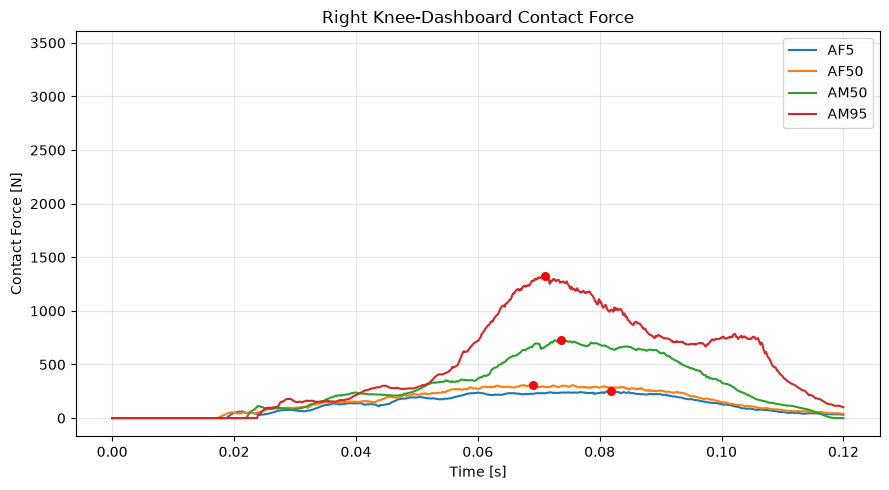

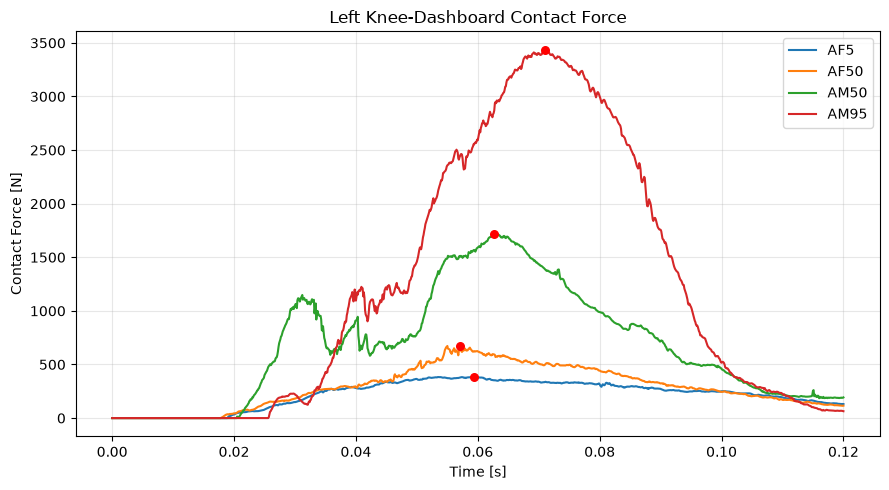

In [15]:
# Auswertung Kontakt Knie vs. Dashboard

def print_contact_results(result_knee_right, result_knee_left):
    # Textausgabe im Notebook
    print("Knee-Dashboard Contact right")
    print(f"Peak:       {result_knee_right['Peak']:.1f} N")
    print(f"Peak-time:  {result_knee_right['Peak_Zeit']:.4f} s")
    print(f"Impulse:    {result_knee_right['Impuls']:.2f} N·s")
    print()

    print("Knee-Dashboard Contact left")
    print(f"Peak:       {result_knee_left['Peak']:.1f} N")
    print(f"Peak-time:  {result_knee_left['Peak_Zeit']:.4f} s")
    print(f"Impulse:    {result_knee_left['Impuls']:.2f} N·s")
    print()
    print()

def calc_contact_knee(model):
    model.result_knee_right, model.time_knee_right, model.force_knee_right = (
        evaluate_contact_force(
            model.binout,
            model.CONFIG["contacts"]["knee_dashboard_right"],
            "Knee-Dashboard Kontaktkraft rechts"
        )
    )

    model.result_knee_left, model.time_knee_left, model.force_knee_left = (
        evaluate_contact_force(
            model.binout,
            model.CONFIG["contacts"]["knee_dashboard_left"],
            "Knee-Dashboard Kontaktkraft links"
        )
    )
    if log_level >= FULL:
        print(model.NAME + ":\n")
        print_contact_results(model.result_knee_right, model.result_knee_left)
        
for model in models:
    calc_contact_knee(model)
    

#### Gemeinsamer Plot Rechts ####
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_right,
        model.force_knee_right,
        label=model.NAME
    )
    
    plt.scatter(
        model.result_knee_right["Peak_Zeit"],
        model.result_knee_right["Peak"],
        s=30,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Right Knee-Dashboard Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("force_knee_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_contact_knee_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

#### Gemeinsamer Plot Rechts ####
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_left,
        model.force_knee_left,
        label=model.NAME
    )
    
    plt.scatter(
        model.result_knee_left["Peak_Zeit"],
        model.result_knee_left["Peak"],
        s=30,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Left Knee-Dashboard Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("force_knee_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_contact_knee_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

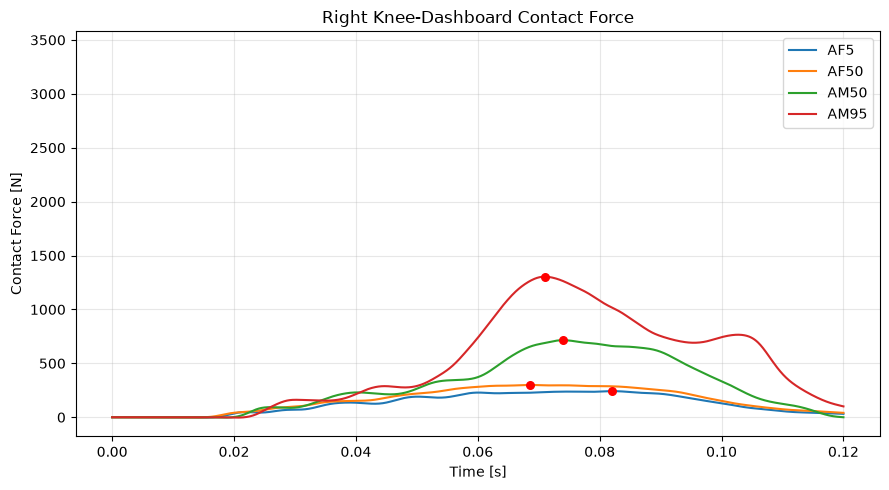

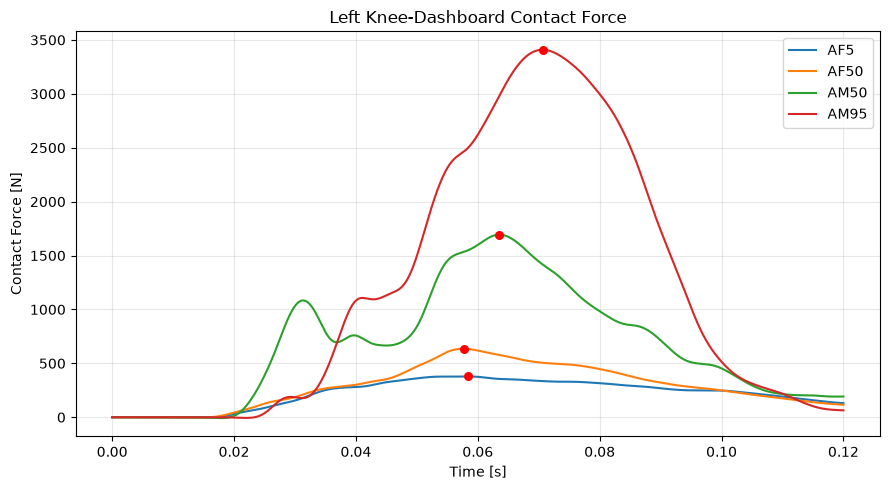

In [16]:
# Signale filtern

# erster Kontakt ab 10 N
CONTACT_THRESHOLD = 10.0  # N

def first_contact_time(tSime, force, threshold=CONTACT_THRESHOLD):

    mask = force >= threshold

    if not np.any(mask):
        return np.nan

    i_first = np.argmax(mask)

    return tSime[i_first]

for model in models:
    model.force_knee_right_filtered = lowpass_filter(
        model.time_knee_right,
        model.force_knee_right
    )

    model.force_knee_left_filtered = lowpass_filter(
        model.time_knee_left,
        model.force_knee_left
    )

    # Peaks der gefilterten Signale bestimmen
    model.idx_peak_right = np.argmax(model.force_knee_right_filtered)
    model.peak_right = model.force_knee_right_filtered[model.idx_peak_right]
    model.peak_time_right = model.time_knee_right[model.idx_peak_right]

    model.idx_peak_left = np.argmax(model.force_knee_left_filtered)
    model.peak_left = model.force_knee_left_filtered[model.idx_peak_left]
    model.peak_time_left = model.time_knee_left[model.idx_peak_left]
    
    model.first_contact_right = first_contact_time(
        model.time_knee_right,
        model.force_knee_right
    )

    model.first_contact_left = first_contact_time(
        model.time_knee_left,
        model.force_knee_left
    )
    
    if log_level >= NORMAL:
        # Ausgabe der gefilterten Peak-Werte
        print(model.NAME + ":\n")
        print("Knee-Dashboard Contact fitered right")
        print(f"Peak filtered:      {model.peak_right:.1f} N")
        print(f"Peak-time filtered: {model.peak_time_right:.4f} s")
        print(f"First contact: {model.first_contact_right:.4f} s")
    
        print()
    
        print("Knee-Dashboard Contact fitered left")
        print(f"Peak filtered:      {model.peak_left:.1f} N")
        print(f"Peak-time filtered: {model.peak_time_left:.4f} s")
        print(f"First contact: {model.first_contact_left:.4f} s")
        
        print()

# ============================================================
# PLOT FILTERED
# ============================================================

# Gemeinsamer Plot Rechts
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_right,
        model.force_knee_right_filtered,
        label=model.NAME
    )
    
    plt.scatter(
        model.peak_time_right,
        model.peak_right,
        s=30,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Right Knee-Dashboard Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("force_knee_right_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_contact_knee_dashboard_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# Gemeinsamer Plot Links
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_left,
        model.force_knee_left_filtered,
        label=model.NAME
    )
    
    plt.scatter(
        model.peak_time_left,
        model.peak_left,
        s=30,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Left Knee-Dashboard Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("force_knee_left_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_contact_knee_dashboard_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

In [17]:
#### Initialer Abstand definiertes Knie-Element zu nächstem Dashboard-Element bei t = 0 ####

import numpy as np

# HILFSFUNKTION: NÄCHSTER PUNKT AUF EINEM DREIECK
def closest_point_on_triangle(p, a, b, c):
    ab = b - a
    ac = c - a
    ap = p - a

    d1 = np.dot(ab, ap)
    d2 = np.dot(ac, ap)

    if d1 <= 0.0 and d2 <= 0.0:
        return a

    bp = p - b
    d3 = np.dot(ab, bp)
    d4 = np.dot(ac, bp)

    if d3 >= 0.0 and d4 <= d3:
        return b

    vc = d1 * d4 - d3 * d2

    if vc <= 0.0 and d1 >= 0.0 and d3 <= 0.0:
        v = d1 / (d1 - d3)
        return a + v * ab

    cp = p - c
    d5 = np.dot(ab, cp)
    d6 = np.dot(ac, cp)

    if d6 >= 0.0 and d5 <= d6:
        return c

    vb = d5 * d2 - d1 * d6

    if vb <= 0.0 and d2 >= 0.0 and d6 <= 0.0:
        w = d2 / (d2 - d6)
        return a + w * ac

    va = d3 * d6 - d5 * d4

    if va <= 0.0 and (d4 - d3) >= 0.0 and (d5 - d6) >= 0.0:
        w = (d4 - d3) / ((d4 - d3) + (d5 - d6))
        return b + w * (c - b)

    denom = 1.0 / (va + vb + vc)

    v = vb * denom
    w = vc * denom

    return a + ab * v + ac * w


# ============================================================
# KNEE-ELEMENT DICHT ABTASTEN
# ============================================================
def sample_quad_surface(xyz, n=11):
    """
    Erzeugt Punkte über die gesamte Fläche eines Quad-Shell-Elements.
    n=11 -> 121 Punkte pro Element.
    """
    p0, p1, p2, p3 = xyz

    points = []

    for i in range(n):
        u = i / (n - 1)

        for j in range(n):
            v = j / (n - 1)

            # bilineare Interpolation über Quad
            p = (1 - u) * (1 - v) * p0 + u * (1 - v) * p1 + u * v * p2 + (1 - u) * v * p3

            points.append(p)

    return np.asarray(points)


# NÄCHSTES DASHBOARD-ELEMENT FINDEN
def initial_knee_dashboard_distance(knee_element_id, shell_ids, shell_nodes, coords, dash_shell_nodes, dash_shell_ids):
    # Knee-Element suchen
    knee_idx = np.where(shell_ids == knee_element_id)[0]

    if len(knee_idx) == 0:
        raise ValueError(f"Knee-Element {knee_element_id} wurde nicht gefunden.")

    knee_idx = knee_idx[0]

    knee_node_indices = shell_nodes[knee_idx]
    knee_xyz = coords[knee_node_indices]

    # gesamte Knee-Elementfläche abtasten
    knee_points = sample_quad_surface(knee_xyz, n=11)

    # Suche über ALLE Dashboard-Elemente
    best_distance = np.inf

    best_knee_point = None
    best_dash_point = None
    best_dash_element = None

    for elem_nodes, elem_id in zip(dash_shell_nodes, dash_shell_ids):
        dash_xyz = coords[elem_nodes]

        # Quad in zwei Dreiecke zerlegen
        triangles = [
            (dash_xyz[0], dash_xyz[1], dash_xyz[2]),
            (dash_xyz[0], dash_xyz[2], dash_xyz[3]),
        ]

        # jeden Punkt der Knee-Fläche prüfen
        for knee_point in knee_points:
            for a, b, c in triangles:
                dash_point = closest_point_on_triangle(knee_point, a, b, c)
                distance = np.linalg.norm(dash_point - knee_point)

                if distance < best_distance:
                    best_distance = distance
                    best_knee_point = knee_point.copy()
                    best_dash_point = dash_point.copy()
                    best_dash_element = int(elem_id)

    # Komponenten zwischen den nächstgelegenen Punkten
    delta = best_dash_point - best_knee_point

    distance_x = abs(delta[0])
    distance_y = abs(delta[1])
    distance_z = abs(delta[2])

    return {
        "knee_element": knee_element_id,
        "dashboard_element": best_dash_element,

        "distance_3d": best_distance,

        "distance_x": distance_x,
        "distance_y": distance_y,
        "distance_z": distance_z,

        "knee_point": best_knee_point,
        "dashboard_point": best_dash_point,
    }


# D3PLOT-DATEN in Model aufbereiten
for model in models:
    model.coords = np.asarray(model.d3plot.arrays["node_coordinates"])
    model.shell_nodes = np.asarray(model.d3plot.arrays["element_shell_node_indexes"])
    model.shell_parts = np.asarray(model.d3plot.arrays["element_shell_part_indexes"])
    model.shell_ids = np.asarray(model.d3plot.arrays["element_shell_ids"])
    model.part_ids = np.asarray(model.d3plot.arrays["part_ids"])

    # ============================================================
    # DASHBOARD-PART FINDEN
    # ============================================================
    dash_idx = np.where(model.part_ids == model.CONFIG["elements"]["dashboard"])[0]

    if len(dash_idx) == 0:
        raise ValueError(f"Dashboard-Part {model.CONFIG["elements"]["dashboard"]} wurde nicht gefunden.")

    dash_part_index = dash_idx[0]

    dash_mask = model.shell_parts == dash_part_index

    model.dash_shell_nodes = model.shell_nodes[dash_mask]
    model.dash_shell_ids = model.shell_ids[dash_mask]

    if log_level >= NORMAL:
        print(f"Dashboard-Part {model.CONFIG["elements"]["dashboard"]}: {len(model.dash_shell_ids)} Shell-Elemente")
        print()

    # ============================================================
    # RECHTS / LINKS
    # ============================================================
    model.right_initial_knee_dashboard_distance = initial_knee_dashboard_distance(
        # RIGHT_KNEE_ELEMENT
        model.CONFIG["elements"]["right_knee"],
        model.shell_ids,
        model.shell_nodes,
        model.coords,
        model.dash_shell_nodes,
        model.dash_shell_ids
    )

    model.left_initial_knee_dashboard_distance = initial_knee_dashboard_distance(
        # LEFT_KNEE_ELEMENT
        model.CONFIG["elements"]["left_knee"],
        model.shell_ids,
        model.shell_nodes,
        model.coords,
        model.dash_shell_nodes,
        model.dash_shell_ids
    )

    # ============================================================
    # AUSGABE
    # ============================================================
    if log_level >= NORMAL:
        print(model.NAME + ":\n")

        for name, result in [
            ("RIGHT KNEE", model.right_initial_knee_dashboard_distance),
            ("LEFT KNEE", model.left_initial_knee_dashboard_distance),
        ]:
            print(name)
            print(f"Knee-Element: {result['knee_element']}")
            print(f"Nächstes Dashboard-Element: {result['dashboard_element']}")
            print(f"3D-Abstand: {result['distance_3d']:.2f} mm")
            print(f"X-Anteil: {result['distance_x']:.2f} mm")
            print(f"Y-Anteil: {result['distance_y']:.2f} mm")
            print(f"Z-Anteil: {result['distance_z']:.2f} mm")
            print("Punkt Knee:", result["knee_point"])
            print("Punkt Dashboard:", result["dashboard_point"])
            print()

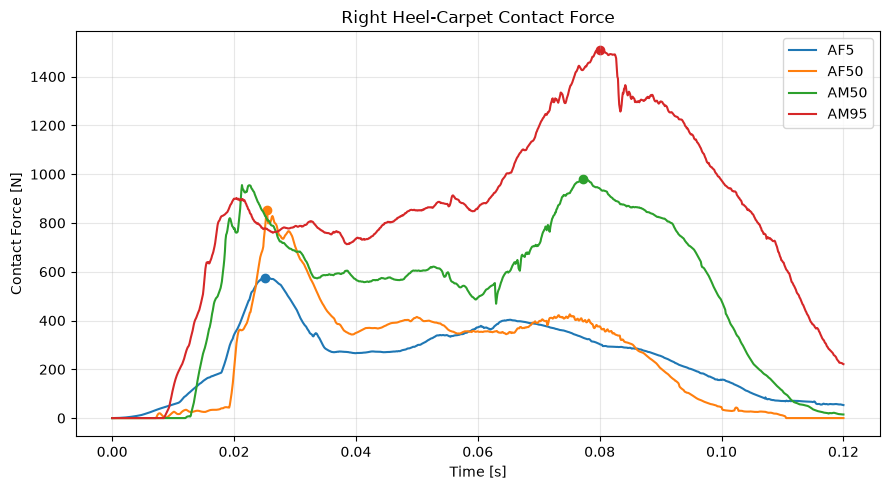

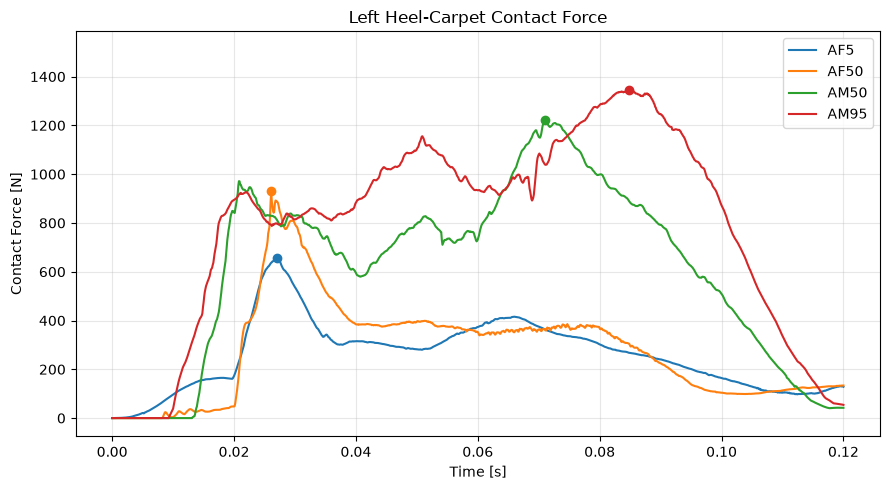

In [18]:
# HEEL-CARPET KONTAKTKRAFT

for model in models:
    # Rohdaten auswerten
    model.result_heel_right, model.time_heel_right, model.force_heel_right = (
        evaluate_contact_force(
            model.binout,
            model.CONFIG["contacts"]["heel_carpet_right"],
            "Heel-Carpet Contact-Force right"
        )
    )

    model.result_heel_left, model.time_heel_left, model.force_heel_left = (
        evaluate_contact_force(
            model.binout,
            model.CONFIG["contacts"]["heel_carpet_left"],
            "Heel-Carpet Contact-Force left"
        )
    )

# PLOT UNFILTERED Right

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_heel_right,
        model.force_heel_right,
        label=model.NAME
    )

    plt.scatter(
        model.result_heel_right["Peak_Zeit"],
        model.result_heel_right["Peak"]
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Right Heel-Carpet Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("force_heel_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(
        OUTPUT_DIR / "right_heel_carpet_contact_force.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# PLOT UNFILTERED Left

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_heel_left,
        model.force_heel_left,
        label=model.NAME
    )

    plt.scatter(
        model.result_heel_left["Peak_Zeit"],
        model.result_heel_left["Peak"]
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title("Left Heel-Carpet Contact Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("force_heel_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(
        OUTPUT_DIR / "lef_heel_carpet_contact_force.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

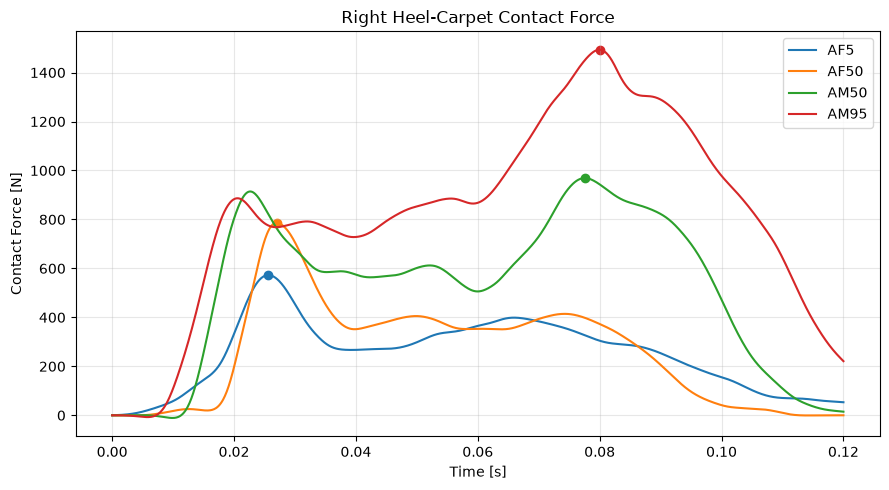

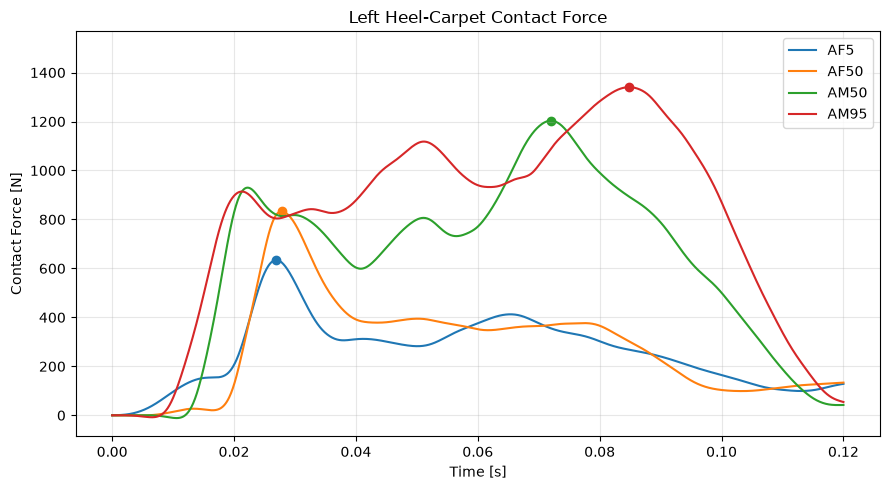

In [19]:
# HEEL-CARPET KONTAKTKRAFT FILTERED

for model in models:

    model.force_heel_right_filtered = lowpass_filter(
        model.time_heel_right,
        model.force_heel_right
    )

    model.force_heel_left_filtered = lowpass_filter(
        model.time_heel_left,
        model.force_heel_left
    )


    # FILTERED PEAKS

    model.i_peak_right_filtered = np.argmax(
        model.force_heel_right_filtered
    )

    model.i_peak_left_filtered = np.argmax(
        model.force_heel_left_filtered
    )

    model.peak_right_filtered = (
        model.force_heel_right_filtered[
            model.i_peak_right_filtered
        ]
    )

    model.peak_left_filtered = (
        model.force_heel_left_filtered[
            model.i_peak_left_filtered
        ]
    )

    model.peak_time_right_filtered = (
        model.time_heel_right[
            model.i_peak_right_filtered
        ]
    )

    model.peak_time_left_filtered = (
        model.time_heel_left[
            model.i_peak_left_filtered
        ]
    )


# PLOT FILTERED Right

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_heel_right,
        model.force_heel_right_filtered,
        label=model.NAME
    )

    plt.scatter(
        model.peak_time_right_filtered,
        model.peak_right_filtered
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title(
    f"Right Heel-Carpet Contact Force"
)

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("force_heel_right_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_heel_carpet_contact_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# PLOT FILTERED Left

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_heel_left,
        model.force_heel_left_filtered,
        label=model.NAME
    )

    plt.scatter(
        model.peak_time_left_filtered,
        model.peak_left_filtered
    )

plt.xlabel("Time [s]")
plt.ylabel("Contact Force [N]")
plt.title(
    f"Left Heel-Carpet Contact Force"
)

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("force_heel_left_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_heel_carpet_contact_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

In [20]:
# HEEL-CARPET ERSTKONTAKT

# erster Kontakt ab 10 N
CONTACT_THRESHOLD = 10.0  # N

def first_contact_time(time, force, threshold=CONTACT_THRESHOLD):

    mask = force >= threshold

    if not np.any(mask):
        return np.nan

    i_first = np.argmax(mask)

    return time[i_first]

for model in models:

    model.first_contact_right = first_contact_time(
        model.time_heel_right,
        model.force_heel_right
    )

    model.first_contact_left = first_contact_time(
        model.time_heel_left,
        model.force_heel_left
    )

In [21]:

# Heel Carpet AUSGABE

if log_level >= NORMAL:
    for model in models:
        print(model.NAME + ":\n")
        print("Heel-Carpet Contact right")
        if log_level>= FULL:
            print(
                f"Raw Peak:       "
                f"{model.result_heel_right['Peak']:.1f} N"
            )
            print(
                f"Raw Peak Time:  "
                f"{model.result_heel_right['Peak_Zeit']:.4f} s"
            )
        print(
            f"Filtered Peak:  "
            f"{model.peak_right_filtered:.1f} N"
        )
        print(
            f"Filtered Time:  "
            f"{model.peak_time_right_filtered:.4f} s"
        )
        print(
            f"Impulse:        "
            f"{model.result_heel_right['Impuls']:.2f} N·s"
        )
        print(f"First contact:  "
            f"{model.first_contact_right:.4f} s"
        )

        print()

        print("Heel-Carpet Contact left")
        if log_level>= FULL:
            print(
                f"Raw Peak:       "
                f"{model.result_heel_left['Peak']:.1f} N"
            )
            print(
                f"Raw Peak Time:  "
                f"{model.result_heel_left['Peak_Zeit']:.4f} s"
            )
        print(
            f"Filtered Peak:  "
            f"{model.peak_left_filtered:.1f} N"
        )
        print(
            f"Filtered Time:  "
            f"{model.peak_time_left_filtered:.4f} s"
        )
        print(
            f"Impulse:        "
            f"{model.result_heel_left['Impuls']:.2f} N·s"
        )
        print(f"First contact:  "
            f"{model.first_contact_left:.4f} s"
        )
        
        print()

In [22]:
# Was kann secforce alles ausgeben
if log_level >= FULL:
    for model in models:
        show_binout_content(model.binout, "secforc")


def evaluate_cross_section(section_id, name, binout):
    folder = "secforc"

    time = read_binout(model.binout, folder, "time")
    ids = read_binout(model.binout, folder, "ids")

    fx_all = read_binout(binout, folder, "x_force")
    fy_all = read_binout(binout, folder, "y_force")
    fz_all = read_binout(binout, folder, "z_force")

    mx_all = read_binout(binout, folder, "x_moment")
    my_all = read_binout(binout, folder, "y_moment")
    mz_all = read_binout(binout, folder, "z_moment")

    fx = extract_signal_by_id(fx_all, ids, section_id)
    fy = extract_signal_by_id(fy_all, ids, section_id)
    fz = extract_signal_by_id(fz_all, ids, section_id)

    mx = extract_signal_by_id(mx_all, ids, section_id)
    my = extract_signal_by_id(my_all, ids, section_id)
    mz = extract_signal_by_id(mz_all, ids, section_id)

    force_res = resultant(fx, fy, fz)
    moment_res = resultant(mx, my, mz)

    force_peak, force_peak_time = peak_value_and_time(time, force_res)
    moment_peak, moment_peak_time = peak_value_and_time(time, moment_res)

    result = {
        "Messgroesse": name,

        "Force_Peak": force_peak,
        "Force_Peak_Time": force_peak_time,

        "Moment_Peak": moment_peak,
        "Moment_Peak_Time": moment_peak_time,
    }

    return result, time, force_res, moment_res

In [23]:
for model in models:
    sec_ids = np.asarray(
        model.binout.read("secforc", "ids")
    )

    sec_area = np.asarray(
        model.binout.read("secforc", "area")
    )

    if log_level >= NORMAL:
        print("######### CROSS-SECTION #########")
            
    for name, section_id in model.CONFIG["sections"].items():

        idx = np.where(
            sec_ids == section_id
        )[0]

        if len(idx) == 0:
            print(f"{name}: nicht gefunden")
            continue

        i = idx[0]

        area_values = sec_area[:, i]

        valid = area_values > 0

        if not np.any(valid):
            print(f"{name}: keine gültige Fläche")
            continue

        first_valid_index = np.where(valid)[0][0]

        area_value = area_values[
            first_valid_index
        ]
        
        if log_level >= NORMAL:
            print(
                f"{name}: "
                f"{area_value:.2f} mm²"
            )

    if log_level >= NORMAL:
        print()

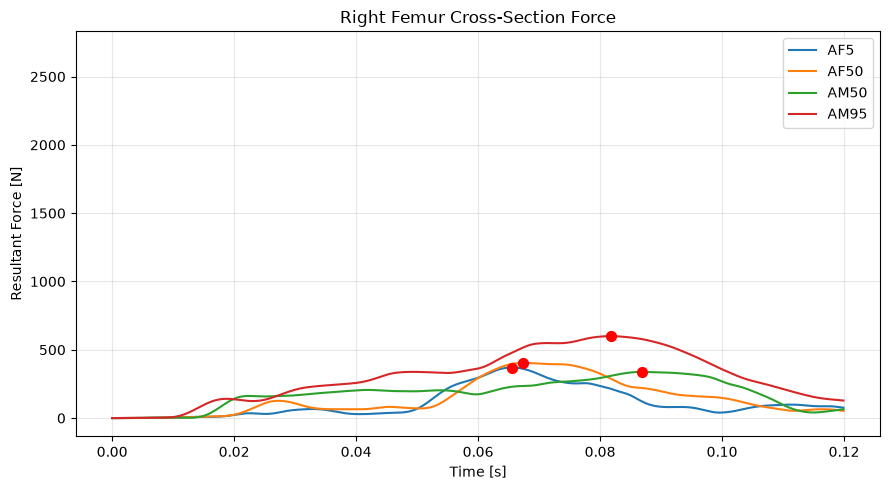

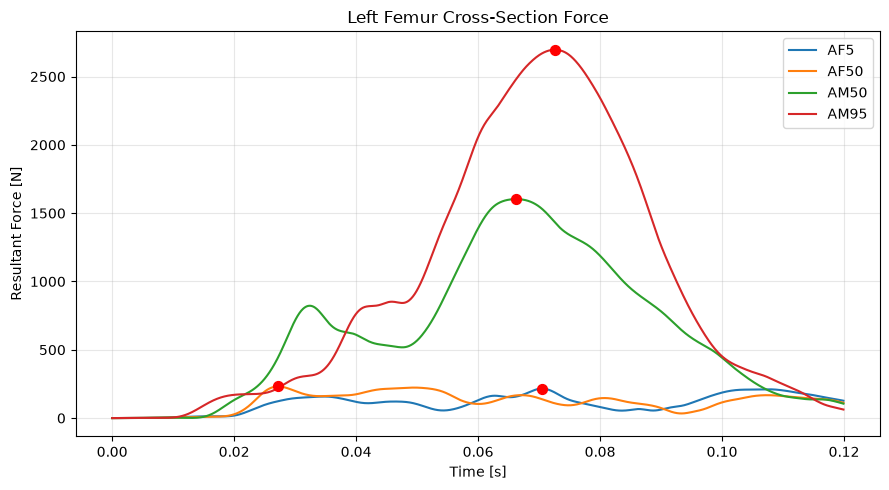

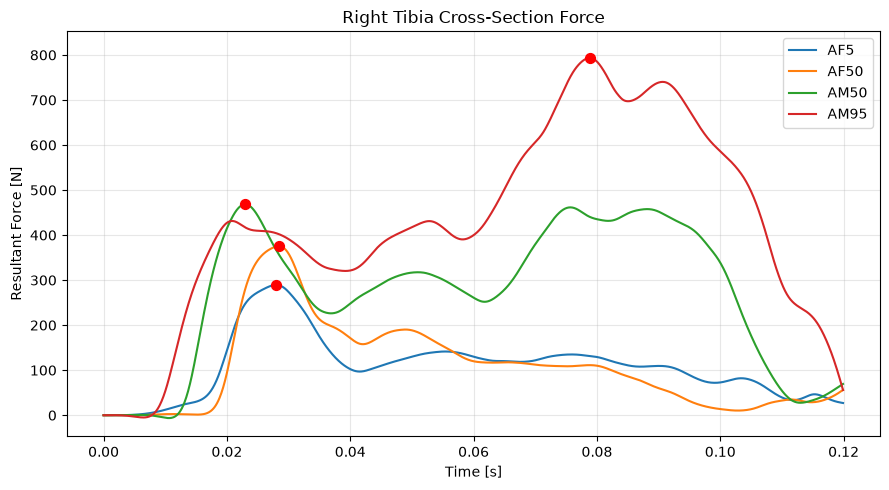

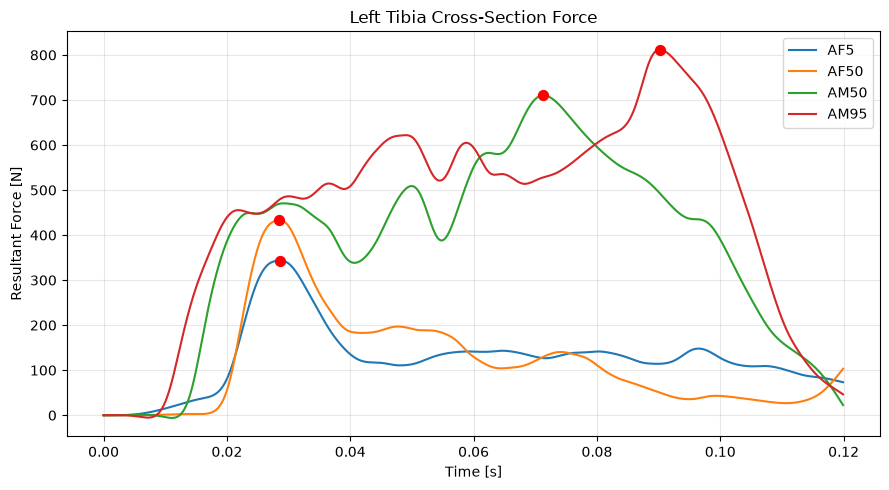

In [24]:
#Auswertung cross-section Femur und Tibia mit Filter
def calc_cross_section(model):
    print(model.NAME + ":\n")
    
    femur_right = evaluate_cross_section(
        model.CONFIG["sections"]["femur_right"],
        "Femur rechts",
        model.binout
    )

    femur_left = evaluate_cross_section(
        model.CONFIG["sections"]["femur_left"],
        "Femur links",
        model.binout
    )

    model.cross_section_result_femur_right, model.cross_section_time_femur_right, model.cross_section_force_femur_right, model.cross_section_moment_femur_right = femur_right
    model.cross_section_result_femur_left, model.cross_section_time_femur_left, model.cross_section_force_femur_left, model.cross_section_moment_femur_left = femur_left

    model.cross_section_force_femur_right_filt = lowpass_filter(
        model.cross_section_time_femur_right,
        model.cross_section_force_femur_right
    )

    model.cross_section_force_femur_left_filt = lowpass_filter(
        model.cross_section_time_femur_left,
        model.cross_section_force_femur_left
    )

    model.cross_section_moment_femur_right_filt = lowpass_filter(
        model.cross_section_time_femur_right,
        model.cross_section_moment_femur_right
    )

    model.cross_section_moment_femur_left_filt = lowpass_filter(
        model.cross_section_time_femur_left,
        model.cross_section_moment_femur_left
    )  

    # Peaks aus den gefilterten Signalen bestimmen
    model.cross_section_peak_femur_right, model.cross_section_t_peak_femur_right = peak_value_and_time(
        model.cross_section_time_femur_right,
        model.cross_section_force_femur_right_filt
    )

    model.cross_section_peak_femur_left, model.cross_section_t_peak_femur_left = peak_value_and_time(
        model.cross_section_time_femur_left,
        model.cross_section_force_femur_left_filt
    )
    
    if log_level >= NORMAL:
            print("Femur-cross-section right")
            print(f"Peak:      {model.cross_section_peak_femur_right:.1f} N")
            print(f"Peak time: {model.cross_section_t_peak_femur_right:.4f} s")
    
            print()
    
            print("Femur-cross-section left")
            print(f"Peak:      {model.cross_section_peak_femur_left:.1f} N")
            print(f"Peak time: {model.cross_section_t_peak_femur_left:.4f} s")
            
            print()
    
    # Tibia
    
    tibia_right = evaluate_cross_section(
        model.CONFIG["sections"]["tibia_right"],
        "Tibia rechts",
        model.binout
    )

    tibia_left = evaluate_cross_section(
        model.CONFIG["sections"]["tibia_left"],
        "Tibia links",
        model.binout
    )
    
    model.cross_section_result_tibia_right, model.cross_section_time_tibia_right, model.cross_section_force_tibia_right, model.cross_section_moment_tibia_right = tibia_right
    model.cross_section_result_tibia_left, model.cross_section_time_tibia_left, model.cross_section_force_tibia_left, model.cross_section_moment_tibia_left = tibia_left
        
    model.cross_section_force_tibia_right_filt = lowpass_filter(
        model.cross_section_time_tibia_right,
        model.cross_section_force_tibia_right
    )
    
    model.cross_section_force_tibia_left_filt = lowpass_filter(
        model.cross_section_time_tibia_left,
        model.cross_section_force_tibia_left
    )

    model.cross_section_peak_tibia_right, model.cross_section_t_peak_tibia_right = peak_value_and_time(
        model.cross_section_time_tibia_right,
        model.cross_section_force_tibia_right_filt
    )

    model.cross_section_peak_tibia_left, model.cross_section_t_peak_tibia_left = peak_value_and_time(
        model.cross_section_time_tibia_left,
        model.cross_section_force_tibia_left_filt
    )
    
    if log_level >= NORMAL:
        print("Tibia cross-section right")
        print(f"Peak:      {model.cross_section_peak_tibia_right:.1f} N")
        print(f"Peak time: {model.cross_section_t_peak_tibia_right:.4f} s")

        print()

        print("Tibia cross-section left")
        print(f"Peak:      {model.cross_section_peak_tibia_left:.1f} N")
        print(f"Peak time: {model.cross_section_t_peak_tibia_left:.4f} s")
        
        print()
    
for model in models:
    calc_cross_section(model)

#Plot right femur
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.cross_section_time_femur_right,
        model.cross_section_force_femur_right_filt,
        label=model.NAME
    )
    
    plt.scatter(
        model.cross_section_t_peak_femur_right,
        model.cross_section_peak_femur_right,
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Force [N]")
plt.title("Right Femur Cross-Section Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("cross_section_force_femur_right_filt")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_Femur_cross-section_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

#Plot left femur
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.cross_section_time_femur_left,
        model.cross_section_force_femur_left_filt,
        label=model.NAME
    )
    
    plt.scatter(
        model.cross_section_t_peak_femur_left,
        model.cross_section_peak_femur_left,
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Force [N]")
plt.title("Left Femur Cross-Section Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("cross_section_force_femur_left_filt")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_Femur_cross-section_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# Plot right tibia
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.cross_section_time_tibia_right,
        model.cross_section_force_tibia_right_filt,
        label=model.NAME
    )

    plt.scatter(
        model.cross_section_t_peak_tibia_right,
        model.cross_section_peak_tibia_right,
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Force [N]")
plt.title("Right Tibia Cross-Section Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("cross_section_force_tibia_right_filt")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_Tibia_cross-section_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# Plot left tibia
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.cross_section_time_tibia_left,
        model.cross_section_force_tibia_left_filt,
        label=model.NAME
    )

    plt.scatter(
        model.cross_section_t_peak_tibia_left,
        model.cross_section_peak_tibia_left,
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Force [N]")
plt.title("Left Tibia Cross-Section Force")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("cross_section_force_tibia_left_filt")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_Tibia_cross-section_force_filtered.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

In [25]:
#Funktion zur Auswertung der Calcaneus-Bewegung (Range = Maximum - Minimum)
def evaluate_calcaneus_displacement(node_ids, name, d3plot):
    indices = get_node_indices(node_ids, d3plot)

    disp_all = np.asarray(
        d3plot.arrays[ArrayType.node_displacement]
    )
 
    # timestep x selected nodes x xyz
    disp_nodes = disp_all[:, indices, :]

    # Mittelwert über die Calcaneus-Nodes
    disp_mean = disp_nodes.mean(axis=1)

    # Komponenten
    disp_x = disp_mean[:, 0]
    disp_y = disp_mean[:, 1]
    disp_z = disp_mean[:, 2]

    # Bewegungsbereiche
    range_x = np.nanmax(disp_x) - np.nanmin(disp_x)
    range_y = np.nanmax(disp_y) - np.nanmin(disp_y)
    range_z = np.nanmax(disp_z) - np.nanmin(disp_z)

    result = {
        "Messgroesse": name,
        "Range_X_mm": range_x,
        "Range_Y_mm": range_y,
        "Range_Z_mm": range_z
    } 

    return result

for model in models:
    result_calc_disp_left = evaluate_calcaneus_displacement(
        model.CONFIG["nodes"]["calcaneus_left"],
        "Calcaneus left",
        model.d3plot
    )

    result_calc_disp_right = evaluate_calcaneus_displacement(
        model.CONFIG["nodes"]["calcaneus_right"],
        "Calcaneus right",
        model.d3plot
    )

    if log_level >= NORMAL:
        print("calcaneus-displacement right")
        print(f"Range X: {result_calc_disp_right['Range_X_mm']:.2f} mm")
        print(f"Range Y: {result_calc_disp_right['Range_Y_mm']:.2f} mm")
        print(f"Range Z: {result_calc_disp_right['Range_Z_mm']:.2f} mm")

        print()

        print("calcaneus-displacement left")
        print(f"Range X: {result_calc_disp_left['Range_X_mm']:.2f} mm")
        print(f"Range Y: {result_calc_disp_left['Range_Y_mm']:.2f} mm")
        print(f"Range Z: {result_calc_disp_left['Range_Z_mm']:.2f} mm")

        print()


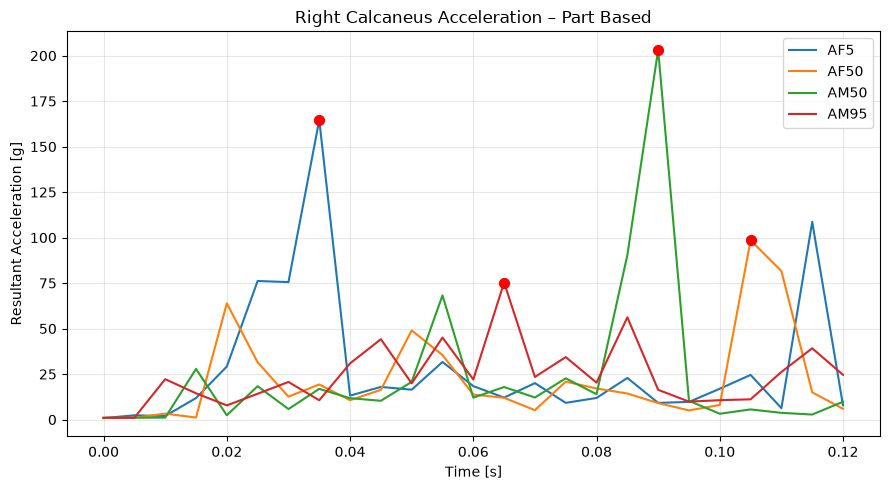

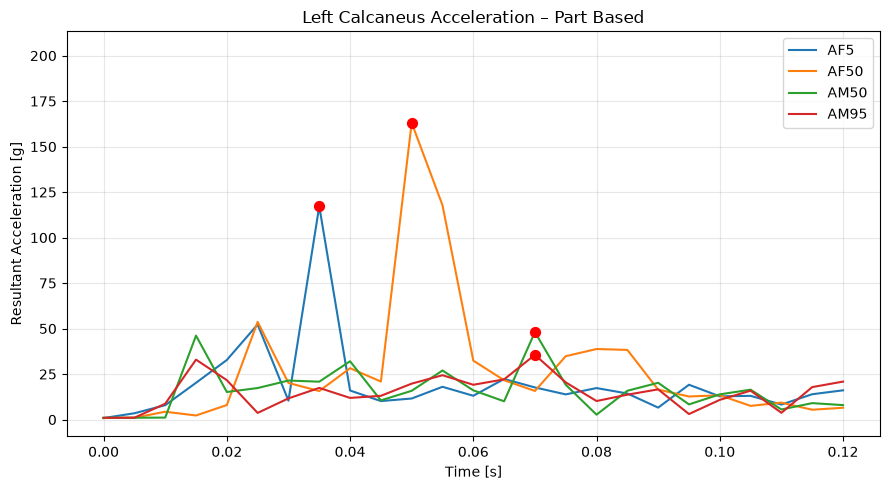

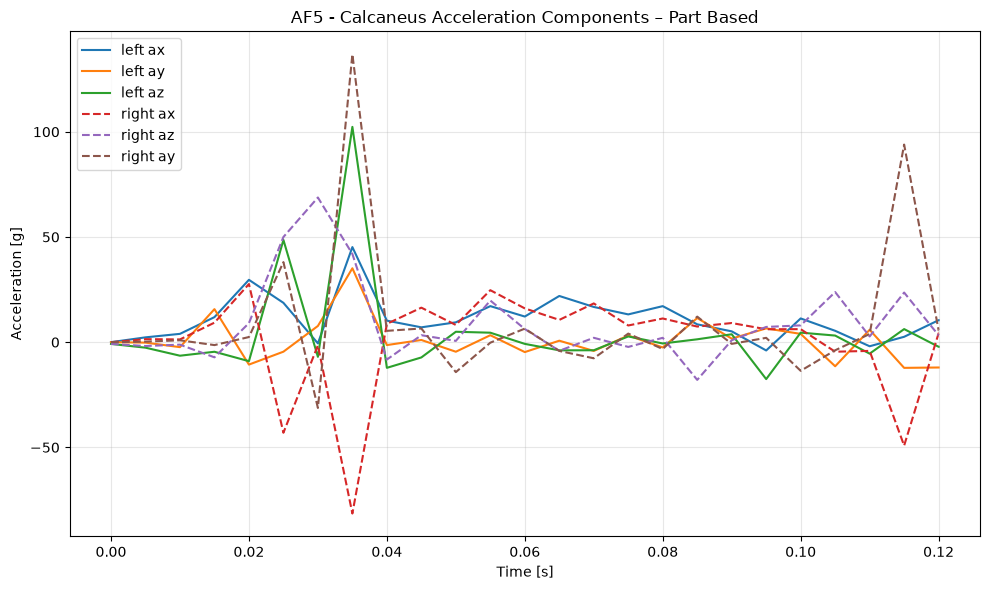

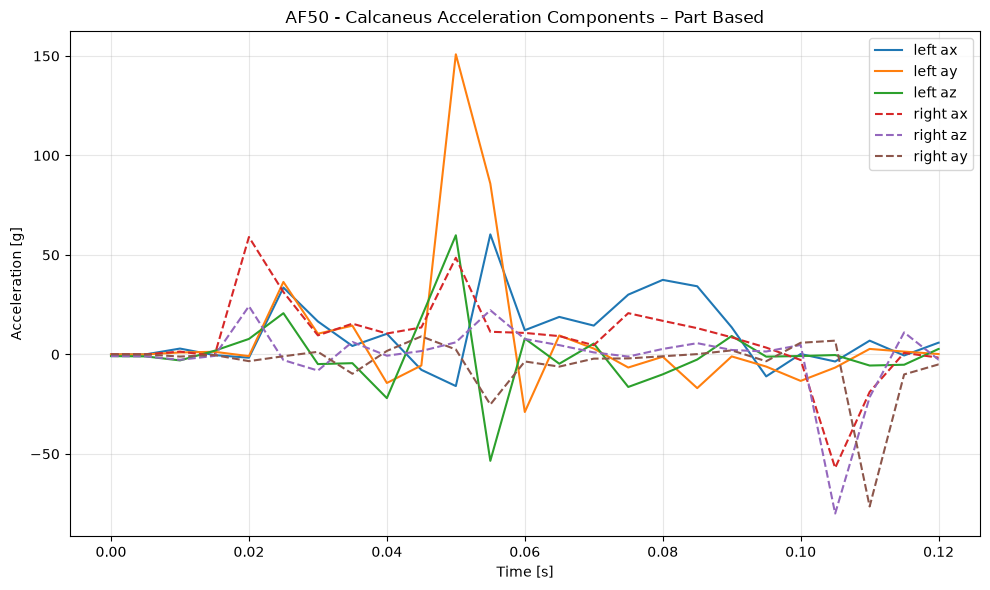

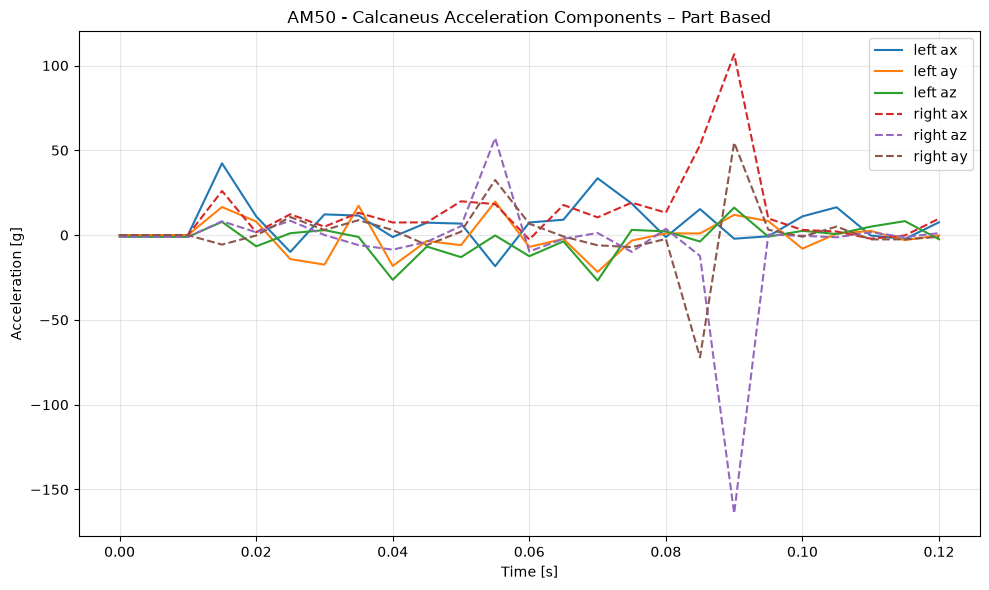

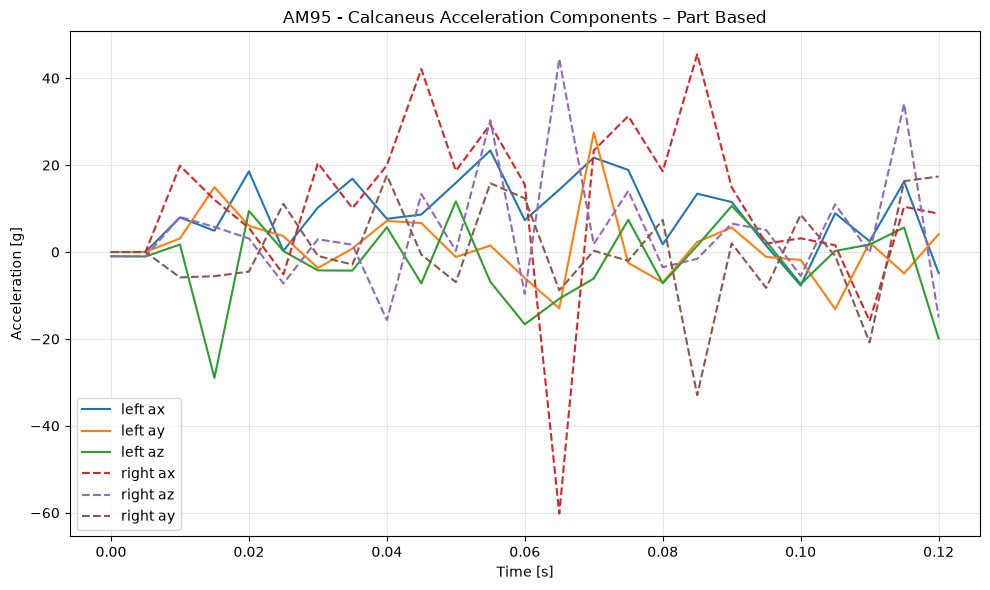

In [26]:
#### Calcaneusbeschleunigung ####
G_FACTOR = 9810.0

# Alle Knoten aus gegebenen Solid-Parts bestimmen
def get_nodes_from_solid_parts(
    d3plot,
    wanted_part_ids
):

    if len(wanted_part_ids) == 0:
        raise ValueError(
            "Keine Part-IDs angegeben."
        )

    part_ids = np.asarray(d3plot.arrays[ArrayType.part_ids])
    solid_part_indexes = np.asarray(d3plot.arrays[ArrayType.element_solid_part_indexes])
    solid_node_indexes = np.asarray(d3plot.arrays[ArrayType.element_solid_node_indexes])
    solid_part_ids = part_ids[solid_part_indexes]

    # gewünschte Elemente auswählen
    element_mask = np.isin(solid_part_ids, wanted_part_ids)

    selected_elements = solid_node_indexes[element_mask]

    if selected_elements.size == 0:
        raise ValueError(
            f"Keine Solid-Elemente für Part-IDs "
            f"{wanted_part_ids} gefunden."
        )

    # alle Node-Indizes sammeln
    node_indices = np.unique(selected_elements.flatten())

    # ungültige Indizes entfernen
    number_of_nodes = len(d3plot.arrays[ArrayType.node_ids])

    node_indices = node_indices[(node_indices >= 0) & (node_indices < number_of_nodes)]

    # tatsächliche LS-DYNA Node-IDs
    node_ids = np.asarray(d3plot.arrays[ArrayType.node_ids])[node_indices]


    return (
        node_indices,
        node_ids
    )

# Part-basierte Calcaneus-Beschleunigung
def evaluate_calcaneus_part_acceleration(
    d3plot,
    wanted_part_ids,
    name,
    g_factor=9810.0
):
    # zugehörige Calcaneus-Knoten bestimmen
    node_indices, node_ids = (get_nodes_from_solid_parts(d3plot,wanted_part_ids))
    acc_all = np.asarray(d3plot.arrays[ArrayType.node_acceleration])
    acc_nodes = acc_all[:,node_indices,:]
    acc_mean_xyz = np.mean(acc_nodes,axis=1)
    acc_resultant = np.linalg.norm(acc_mean_xyz,axis=1)
    acc_g = (acc_resultant/g_factor)

    try:
        time = np.asarray(d3plot.arrays[ArrayType.timesteps])
    except Exception:
        time = get_d3plot_time(d3plot)

    # Peak bestimmen
    peak_index = np.argmax(acc_g)
    peak_g = acc_g[peak_index]
    peak_time = time[peak_index]

    result = {
        "Messgroesse": name,
        "Peak_g": float(peak_g),
        "Peak_Zeit": float(peak_time),
        "Anzahl_Knoten": len(node_indices),
        "Node_IDs": node_ids
    }

    return (
        result,
        time,
        acc_g,
        acc_mean_xyz,
        node_ids
    )

for model in models:
    # rechter Calcaneus
    (
        model.calc_acc_right,
        model.calc_acc_time_right,
        model.calc_acc_g_right,
        model.calc_acc_xyz_right,
        model.calc_node_ids_right
    ) = evaluate_calcaneus_part_acceleration(
        model.d3plot,
        model.CONFIG["parts"]["calcaneus_right"],
        "Calcaneus acceleration right",
        g_factor=G_FACTOR
    )

    #linker Calcaneus
    (
        model.calc_acc_left,
        model.calc_acc_time_left,
        model.calc_acc_g_left,
        model.calc_acc_xyz_left,
        model.calc_node_ids_left
    ) = evaluate_calcaneus_part_acceleration(
        model.d3plot,
        model.CONFIG["parts"]["calcaneus_left"],
        "Calcaneus acceleration left",
        g_factor=G_FACTOR
    )
    #Ergebnisse
    if log_level >= FULL:
        print(model.NAME + ":\n")
        print("Calcaneus-accerlation")
        print("left")
        print(
            f"Anzahl Knoten:      "
            f"{model.result_calc_left['Anzahl_Knoten']}"
        )
        print(
            f"Peak acceleration:  "
            f"{model.result_calc_left['Peak_g']:.2f} g"
        )
        print(
            f"Peak time:          "
            f"{model.result_calc_left['Peak_Zeit']:.4f} s"
        )
        print()
        print("right")
        print(
            f"Anzahl Knoten:      "
            f"{model.result_calc_right['Anzahl_Knoten']}"
        )
        print(
            f"Peak acceleration:  "
            f"{model.result_calc_right['Peak_g']:.2f} g"
        )
        print(
            f"Peak time:          "
            f"{model.result_calc_right['Peak_Zeit']:.4f} s"
        )
        print()

# PLOT UNFILTERED

#Plot right
plt.figure(
    figsize=(9, 5)
)

for model in models:
    plt.plot(
        model.calc_acc_time_right,
        model.calc_acc_g_right,
        label=model.NAME
    )

    plt.scatter(
        model.calc_acc_right[
            "Peak_Zeit"
        ],
        model.calc_acc_right[
            "Peak_g"
        ],
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Acceleration [g]")
plt.title("Right Calcaneus Acceleration – Part Based")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("calc_acc_g_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(model.OUTPUT_DIR / "right_Calcaneus_acceleration_part_based.png", dpi=300,bbox_inches="tight")


plt.show()
plt.close()

#Plot left
plt.figure(
    figsize=(9, 5)
)

for model in models:
    plt.plot(
        model.calc_acc_time_left,
        model.calc_acc_g_left,
        label=model.NAME
    )

    plt.scatter(
        model.calc_acc_left[
            "Peak_Zeit"
        ],
        model.calc_acc_left[
            "Peak_g"
        ],
        s=50,
        color="red",
        zorder=5
    )

plt.xlabel("Time [s]")
plt.ylabel("Resultant Acceleration [g]")
plt.title("Left Calcaneus Acceleration – Part Based")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("calc_acc_g_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Calcaneus_acceleration_part_based.png", dpi=300,bbox_inches="tight")


plt.show()
plt.close()



for model in models:

    # optionaler Plot: x-, y-, z-Komponenten


    plt.figure(figsize=(10, 6))


    # LEFT
    plt.plot(model.calc_acc_time_left, model.calc_acc_xyz_left[:, 0] / G_FACTOR, label="left ax")
    plt.plot(model.calc_acc_time_left, model.calc_acc_xyz_left[:, 1] / G_FACTOR, label="left ay")
    plt.plot(model.calc_acc_time_left, model.calc_acc_xyz_left[:, 2] / G_FACTOR, label="left az")
    #RIGHT
    plt.plot(model.calc_acc_time_right, model.calc_acc_xyz_right[:, 0] / G_FACTOR, label="right ax", linestyle="--" )
    plt.plot(model.calc_acc_time_right, model.calc_acc_xyz_right[:, 2] / G_FACTOR, label="right az", linestyle="--")
    plt.plot(model.calc_acc_time_right, model.calc_acc_xyz_right[:, 1] / G_FACTOR, label="right ay", linestyle="--")
    plt.xlabel("Time [s]")
    plt.ylabel("Acceleration [g]")
    plt.title(model.NAME + " - Calcaneus Acceleration Components – Part Based")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

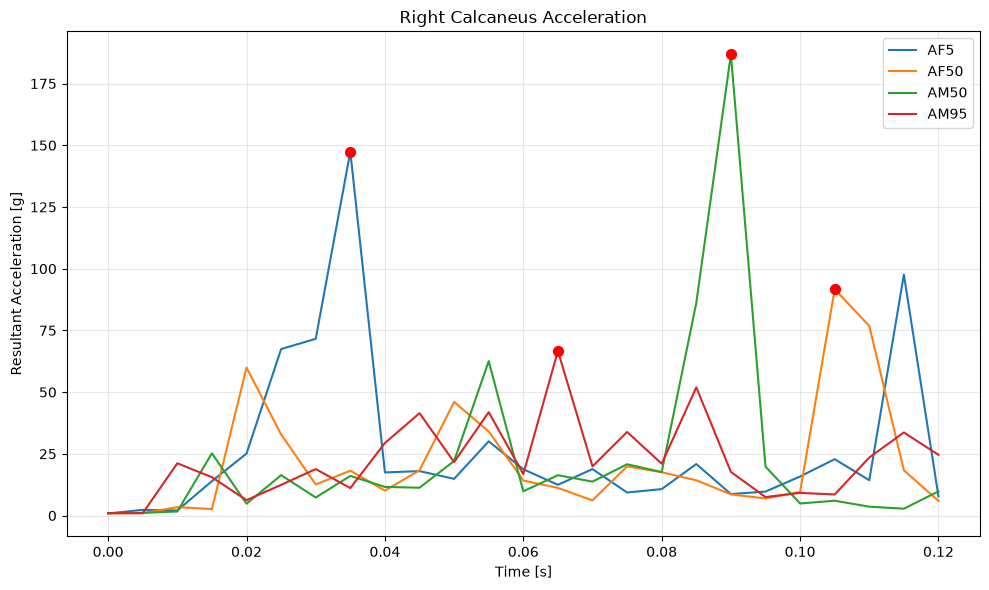

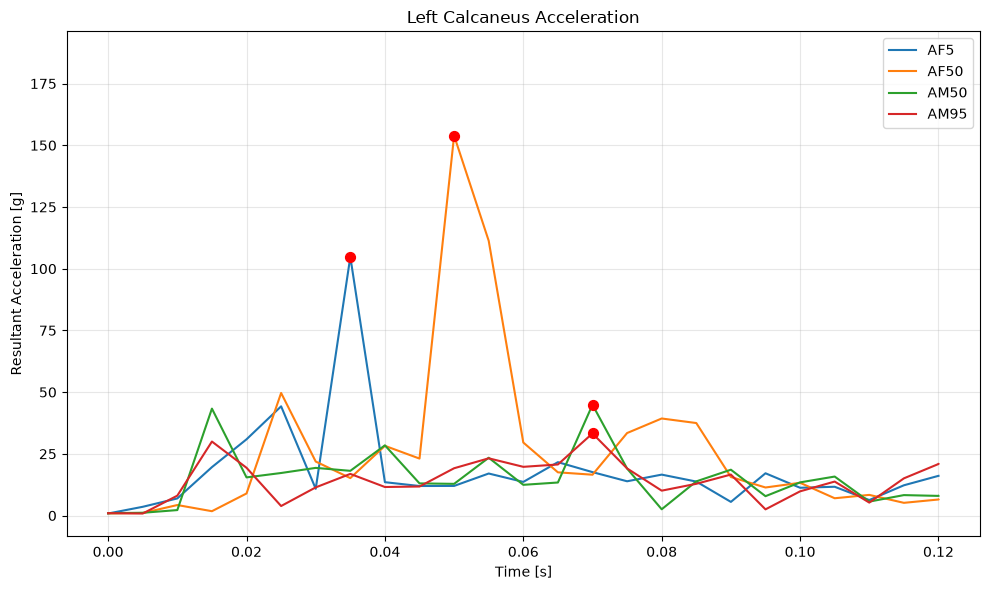

In [27]:
# Calcaneus Beschleunigung gefiltert

G_FACTOR = 9810.0  # mm/s² pro g

def filter_calc_acc(model):
    dt = np.mean(np.diff(model.calc_acc_time_right))
    fs = 1.0 / dt
    nyquist = fs / 2.0

    if log_level >= NORMAL:
        print("Filter info:")
        print(f"Mittleres dt:       {dt:.6f} s")
        print(f"Sampling-Frequenz:  {fs:.2f} Hz")
        print(f"Nyquist-Frequenz:   {nyquist:.2f} Hz")
        print(f"Cutoff:              {CUTOFF_HZ:.2f} Hz")
        print(f"Filterordnung:       {FILTER_ORDER}")
        print()

    # Links filtern
    model.calc_acc_xyz_left_filtered = np.zeros_like(model.calc_acc_xyz_left)

    for component in range(3):
        model.calc_acc_xyz_left_filtered[:, component] = lowpass_filter(
            model.calc_acc_time_left,
            model.calc_acc_xyz_left[:, component]
        )

    # Resultierende ERST NACH Filterung bilden
    model.calc_acc_g_left_filtered = np.linalg.norm(model.calc_acc_xyz_left_filtered, axis=1) / G_FACTOR

    # Peak links
    model.calc_acc_peak_index_left_filtered = np.argmax(model.calc_acc_g_left_filtered)
    model.calc_acc_peak_left_filtered = model.calc_acc_g_left_filtered[model.calc_acc_peak_index_left_filtered]
    model.calc_acc_peak_time_left_filtered = model.calc_acc_time_left[model.calc_acc_peak_index_left_filtered]

    # Rechts filtern
    model.calc_acc_xyz_right_filtered = np.zeros_like(model.calc_acc_xyz_right)

    for component in range(3):
        model.calc_acc_xyz_right_filtered[:, component] = lowpass_filter(
            model.calc_acc_time_right,
            model.calc_acc_xyz_right[:, component]
        )

    # Resultierende ERST NACH Filterung bilden
    model.calc_acc_g_right_filtered = np.linalg.norm(model.calc_acc_xyz_right_filtered, axis=1) / G_FACTOR

    # Peak rechts
    model.calc_acc_peak_index_right_filtered = np.argmax(model.calc_acc_g_right_filtered)
    model.calc_acc_peak_right_filtered = model.calc_acc_g_right_filtered[model.calc_acc_peak_index_right_filtered]
    model.calc_acc_peak_time_right_filtered = model.calc_acc_time_right[model.calc_acc_peak_index_right_filtered]

    if log_level >= NORMAL:
        print(model.NAME + ":\n")

        print("left")
        print(f"Raw peak:       {model.calc_acc_left['Peak_g']:.2f} g bei {model.calc_acc_left['Peak_Zeit']:.4f} s")
        print(f"Filtered peak:  {model.calc_acc_peak_left_filtered:.2f} g bei {model.calc_acc_peak_time_left_filtered:.4f} s")
        print()

        print("right")
        print(f"Raw peak:       {model.calc_acc_right['Peak_g']:.2f} g bei {model.calc_acc_right['Peak_Zeit']:.4f} s")
        print(f"Filtered peak:  {model.calc_acc_peak_right_filtered:.2f} g bei {model.calc_acc_peak_time_right_filtered:.4f} s")
        print()
        
print("Calcaneus filtered")
for model in models:
    filter_calc_acc(model)

# PLOT FILTERED

#plot right
plt.figure(figsize=(10, 6))

for model in models:
    plt.plot(model.calc_acc_time_right, model.calc_acc_g_right_filtered, label=model.NAME)
    plt.scatter(model.calc_acc_peak_time_right_filtered, model.calc_acc_peak_right_filtered, s=50, color="red", zorder=5)

plt.xlabel("Time [s]")
plt.ylabel("Resultant Acceleration [g]")
plt.title("Right Calcaneus Acceleration")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("calc_acc_g_right_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_Calcaneus_acceleration_part_filtered.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close()

#plot left
plt.figure(figsize=(10, 6))

for model in models:
    plt.plot(model.calc_acc_time_left, model.calc_acc_g_left_filtered, label=model.NAME)
    plt.scatter(model.calc_acc_peak_time_left_filtered, model.calc_acc_peak_left_filtered, s=50, color="red", zorder=5)

plt.xlabel("Time [s]")
plt.ylabel("Resultant Acceleration [g]")
plt.title("Left Calcaneus Acceleration")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("calc_acc_g_left_filtered")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_Calcaneus_acceleration_part_filtered.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close()

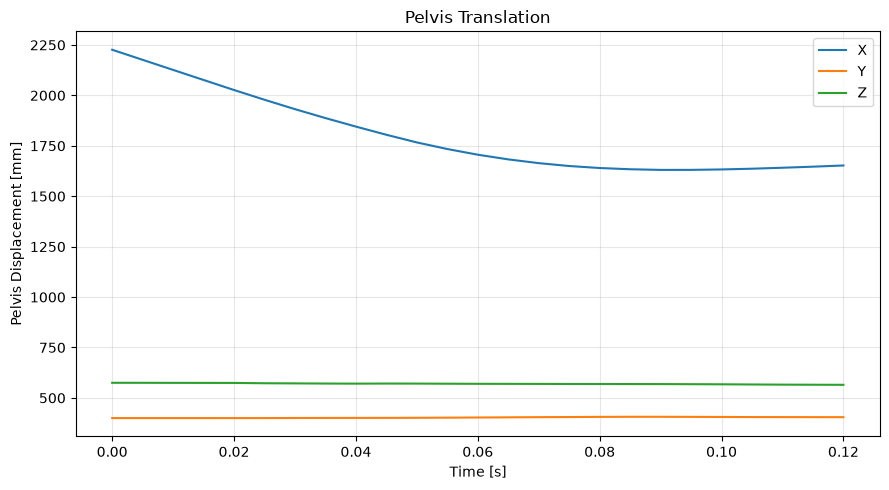

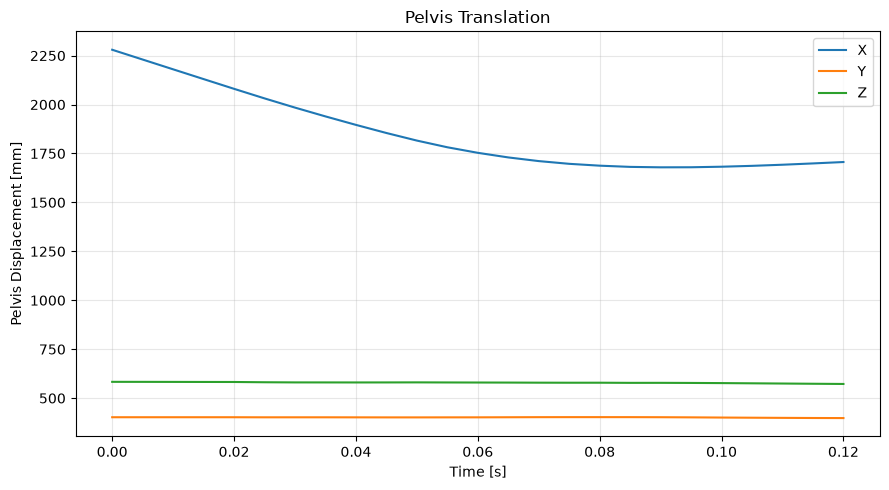

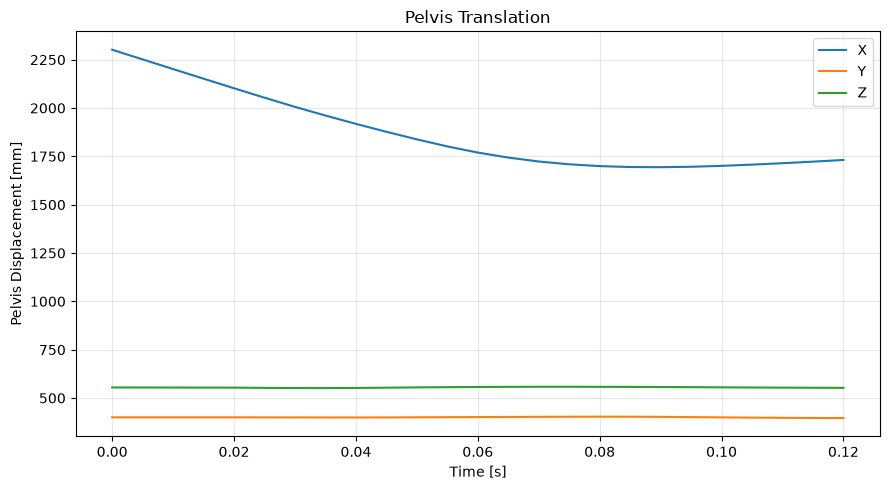

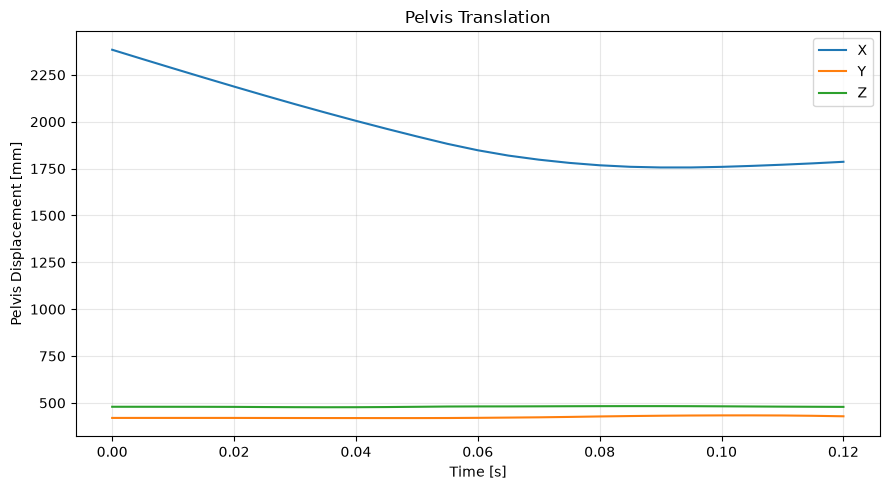

In [28]:
# Funktion zur Auswertung der mittleren Verschiebung von nodes
def evaluate_node_group_displacement(node_ids, name, d3plot):
    indices = get_node_indices(node_ids, d3plot)

    disp_all = np.asarray(d3plot.arrays[ArrayType.node_displacement])

    # timestep x selected nodes x xyz
    disp_nodes = disp_all[:, indices, :]

    # Mittelwert über die Nodes
    disp_mean = disp_nodes.mean(axis=1)

    # Resultierende Verschiebung
    disp_res = np.linalg.norm(disp_mean, axis=1)

    time = get_d3plot_time(d3plot)

    result = {"Messgroesse": name, "Max_Displacement": np.nanmax(disp_res)}

    return result, time, disp_mean, disp_res

for model in models:
    model.result_pelvis, model.time_pelvis, model.disp_pelvis, model.disp_res_pelvis = evaluate_node_group_displacement(model.CONFIG["nodes"]["pelvis"], "Pelvis Translation", model.d3plot)

    if log_level >= FULL:
        print(model.result_pelvis)

    plt.figure(figsize=(9, 5))

    plt.plot(model.time_pelvis, model.disp_pelvis[:, 0], label="X")
    plt.plot(model.time_pelvis, model.disp_pelvis[:, 1], label="Y")
    plt.plot(model.time_pelvis, model.disp_pelvis[:, 2], label="Z")

    plt.xlabel("Time [s]")
    plt.ylabel("Pelvis Displacement [mm]")
    plt.title("Pelvis Translation")

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    if log_level >= NORMAL:
        plt.savefig(model.OUTPUT_DIR / "pelvis_Translation.png", dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

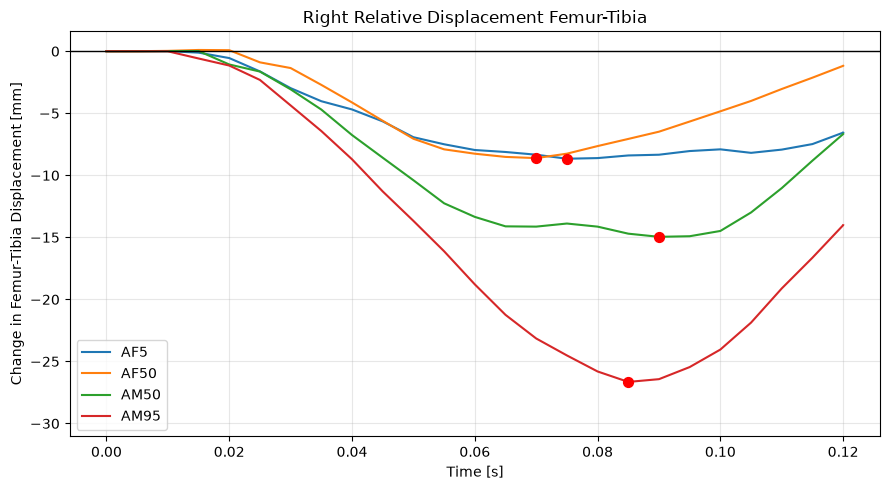

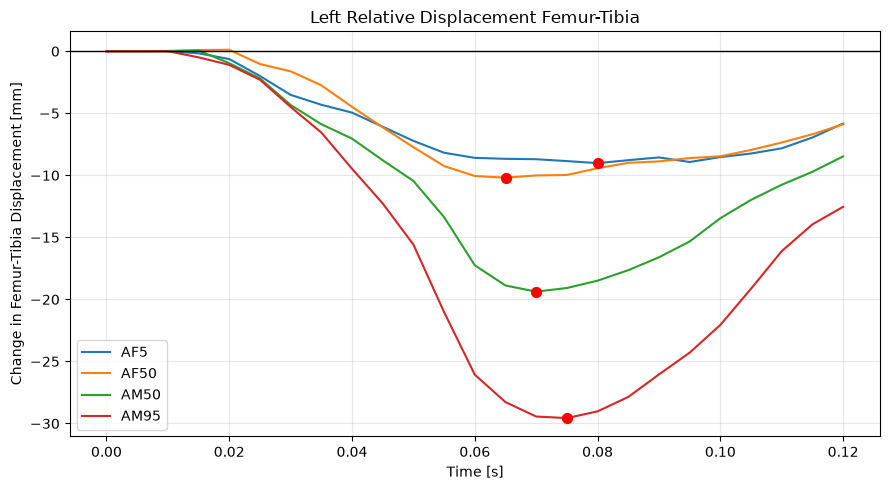

In [29]:
# Funktion für mittleren Abstand zwischen Femur- und Tibia-Nodegruppen // Relative Bewegung von Tibia und Femur zueinander

def evaluate_femur_tibia_displacement(
    model,
    node_ids_femur,
    node_ids_tibia,
    name,
    d3plot
):
    # Node-Indizes
    idx_femur = get_node_indices(node_ids_femur, d3plot)
    idx_tibia = get_node_indices(node_ids_tibia, d3plot)
    # Anfangskoordinaten
    coords = np.asarray(model.d3plot.arrays[ArrayType.node_coordinates])
    # Verschiebungen
    disp = np.asarray(model.d3plot.arrays[ArrayType.node_displacement])
    # Mittlere Anfangsposition Femur
    coord_femur = coords[idx_femur,:].mean(axis=0)
    # Mittlere Anfangsposition Tibia
    coord_tibia = coords[idx_tibia,:].mean(axis=0)

    # Mittlere Verschiebung Femur
    disp_femur = disp[:,idx_femur,:].mean(axis=1)

    # Mittlere Verschiebung Tibia
    disp_tibia = disp[
        :,
        idx_tibia,
        :
    ].mean(axis=1)

    # Aktuelle mittlere Positionen
    pos_femur = (
        coord_femur
        + disp_femur
    )

    pos_tibia = (
        coord_tibia
        + disp_tibia
    )

    # Abstand zwischen den beiden mittleren Positionen
    displacement = np.linalg.norm(
        pos_femur - pos_tibia,
        axis=1
    )

    # Änderung gegenüber Ausgangszustand
    displacement_change = (
        displacement - displacement[0]
    )

    # Zeit
    time = get_d3plot_time(model.d3plot)

    # Größte Annäherung
    min_idx = np.argmin(
        displacement_change
    )

    min_displacement_change = (
        displacement_change[min_idx]
    )

    min_time = time[min_idx]

    # Größte Entfernung
    max_idx = np.argmax(
        displacement_change
    )

    max_displacement_change = (
        displacement_change[max_idx]
    )

    max_time = time[max_idx]

    result = {
        "Messgroesse": name,
        "Initial_Displacement": displacement[0],
        "Min_Displacement_Change": min_displacement_change,
        "Min_Zeit": min_time,
        "Max_Displacement_Change": max_displacement_change,
        "Max_Zeit": max_time
    }

    return (
        result,
        time,
        displacement,
        displacement_change
    )


if log_level >= NORMAL:
    print("Femur-Tibia displacement right")

for model in models:
    (
        model.result_knee_displacement_right,
        model.time_knee_displacement_right,
        model.displacement_right,
        model.displacement_change_right
    ) = evaluate_femur_tibia_displacement(
        model,
        model.CONFIG["nodes"]["femur_right"],
        model.CONFIG["nodes"]["tibia_right"],
        "Femur-Tibia Displacement right",
        model.d3plot
    )

    (
        model.result_knee_displacement_left,
        model.time_knee_displacement_left,
        model.displacement_left,
        model.displacement_change_left
    ) = evaluate_femur_tibia_displacement(
        model,
        model.CONFIG["nodes"]["femur_left"],
        model.CONFIG["nodes"]["tibia_left"],
        "Femur-Tibia Displacement left",
        model.d3plot
    )
    
    if log_level >= NORMAL:
        print(model.NAME + ":\n")
        print("Femur-Tibia displacement right")
        print(
            f"Initial displacement:            "
            f"{model.result_knee_displacement_right['Initial_Displacement']:.3f} mm"
        )

        print(
            f"Maximum approach:            "
            f"{model.result_knee_displacement_right['Min_Displacement_Change']:.3f} mm"
        )

        print(
            f"Time of maximum approach:    "
            f"{model.result_knee_displacement_right['Min_Zeit']:.4f} s"
        )

        print()

        print("Femur-Tibia displacement left")

        print(
            f"Initial displacement:            "
            f"{model.result_knee_displacement_left['Initial_Displacement']:.3f} mm"
        )

        print(
            f"Maximum approach:            "
            f"{model.result_knee_displacement_left['Min_Displacement_Change']:.3f} mm"
        )

        print(
            f"Time of maximum approach:    "
            f"{model.result_knee_displacement_left['Min_Zeit']:.4f} s"
        )

        print()


# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_displacement_right,
        model.displacement_change_right,
        label=model.NAME
    )

    # stärkste Annäherung rechts
    plt.scatter(
        model.result_knee_displacement_right["Min_Zeit"],
        model.result_knee_displacement_right["Min_Displacement_Change"],
        s=50,
        color="red",
        zorder=5
    )

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Time [s]")
plt.ylabel("Change in Femur-Tibia Displacement [mm]")
plt.title("Right Relative Displacement Femur-Tibia")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("displacement_change_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_relative_displacement_Femur_Tibia.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

# Plot left

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_knee_displacement_left,
        model.displacement_change_left,
        label=model.NAME
    )

    # stärkste Annäherung rechts
    plt.scatter(
        model.result_knee_displacement_left["Min_Zeit"],
        model.result_knee_displacement_left["Min_Displacement_Change"],
        s=50,
        color="red",
        zorder=5
    )

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Time [s]")
plt.ylabel("Change in Femur-Tibia Displacement [mm]")
plt.title("Left Relative Displacement Femur-Tibia")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("displacement_change_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_relative_displacement_Femur_Tibia.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

In [30]:
# Gelenkwinkel (Auswahl von 3 Knoten aus ANSA)
def get_node_position_over_time(node_id, d3plot):
    idx = get_node_index(node_id, d3plot)

    coords = np.asarray(d3plot.arrays[ArrayType.node_coordinates])
    disp = np.asarray(d3plot.arrays[ArrayType.node_displacement])

    positions = coords[idx][None, :] + disp[:, idx, :]

    return positions


def calculate_joint_angle_3points(proximal_node, joint_node, distal_node, name, d3plot):
    # Vektor erstellen (ausgehend von gemeinsamem Punkt in Mitte)
    proximal = get_node_position_over_time(proximal_node, d3plot)
    joint = get_node_position_over_time(joint_node, d3plot)
    distal = get_node_position_over_time(distal_node, d3plot)

    vector_proximal = proximal - joint
    vector_distal = distal - joint

    # Vektor normieren
    norm_proximal = np.linalg.norm(vector_proximal, axis=1)
    norm_distal = np.linalg.norm(vector_distal, axis=1)

    if np.any(norm_proximal < 1e-12):
        raise ValueError("Proximaler Referenzpunkt liegt zu nah am Gelenkpunkt.")

    if np.any(norm_distal < 1e-12):
        raise ValueError("Distaler Referenzpunkt liegt zu nah am Gelenkpunkt.")

    unit_proximal = vector_proximal / norm_proximal[:, None]
    unit_distal = vector_distal / norm_distal[:, None]

    # Winkel über Skalarprodukt
    cos_angle = np.sum(unit_proximal * unit_distal, axis=1)
    cos_angle = np.clip(cos_angle, -1.0, 1.0)
    angle_deg = np.degrees(np.arccos(cos_angle))

    # Winkeländerung
    delta_angle_deg = angle_deg - angle_deg[0]

    time = get_d3plot_time(d3plot)

    # größte Winkeländerung
    i_max = np.argmax(np.abs(delta_angle_deg))

    result = {
        "Messgroesse": name,
        "Initial_Angle_deg": angle_deg[0],
        "Min_Angle_deg": np.nanmin(angle_deg),
        "Max_Angle_deg": np.nanmax(angle_deg),
        "Max_Angle_Change_deg": delta_angle_deg[i_max],
        "Angle_at_Max_Change_deg": angle_deg[i_max],
        "Max_Change_Time_s": time[i_max],
    }

    return result, time, angle_deg, delta_angle_deg

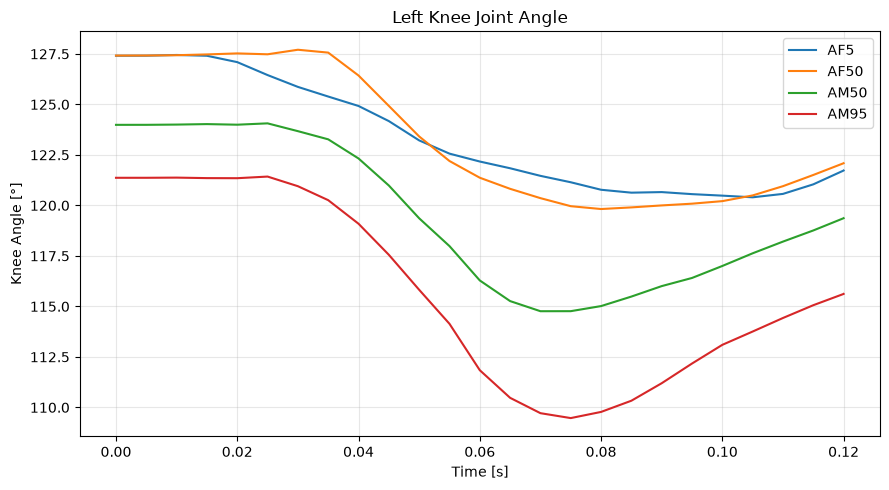

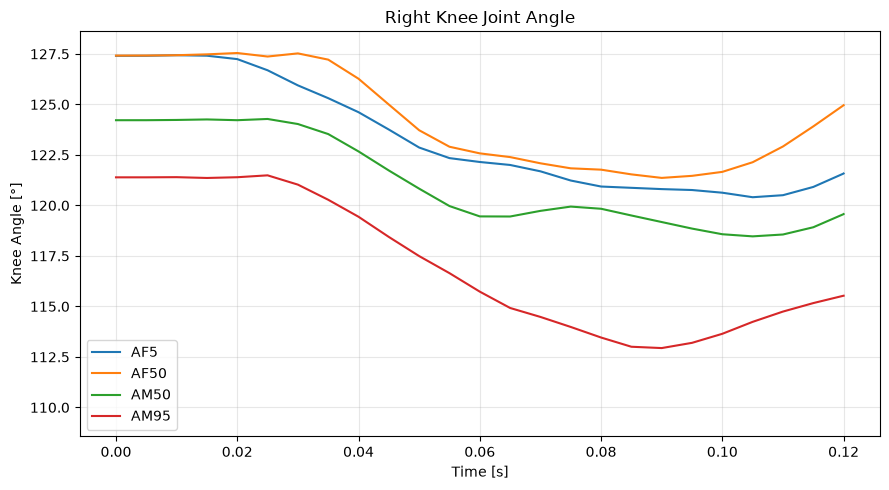

In [31]:
# Knoten festlegen
if log_level >= NORMAL:
    print("######### WINKEL #########")
    
for model in models:
    model.joint_angle_result_knee_right, model.joint_angle_time_knee_right, model.joint_angle_knee_right, model.joint_angle_delta_knee_right = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["knee_right"]["femur"],
        model.CONFIG["nodes"]["knee_right"]["knee"],
        model.CONFIG["nodes"]["knee_right"]["tibia"],
        "Knee angle right",
        model.d3plot
    )

    model.joint_angle_result_knee_left, model.joint_angle_time_knee_left, model.joint_angle_knee_left, model.joint_angle_delta_knee_left = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["knee_left"]["femur"],
        model.CONFIG["nodes"]["knee_left"]["knee"],
        model.CONFIG["nodes"]["knee_left"]["tibia"],
        "Knee angle left",
        model.d3plot
    )
    
    if log_level >= NORMAL:
        print(model.NAME + ":\n")
        print("Knee-angle right")
        print(f"Initial angle:       {model.joint_angle_result_knee_right['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.joint_angle_result_knee_right['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.joint_angle_result_knee_right['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.joint_angle_result_knee_right['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.joint_angle_result_knee_right['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.joint_angle_result_knee_right['Max_Change_Time_s']:.4f} s")

        print()

        print("Knee-angle left")
        print(f"Initial angle:       {model.joint_angle_result_knee_left['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.joint_angle_result_knee_left['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.joint_angle_result_knee_left['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.joint_angle_result_knee_left['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.joint_angle_result_knee_left['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.joint_angle_result_knee_left['Max_Change_Time_s']:.4f} s")
        print()

#Plot left
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.joint_angle_time_knee_left, model.joint_angle_knee_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Knee Angle [°]")
plt.title("Left Knee Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("joint_angle_knee_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Knee_angle.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

#Plot right
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.joint_angle_time_knee_right, model.joint_angle_knee_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Knee Angle [°]")
plt.title("Right Knee Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("joint_angle_knee_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Knee_angle.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

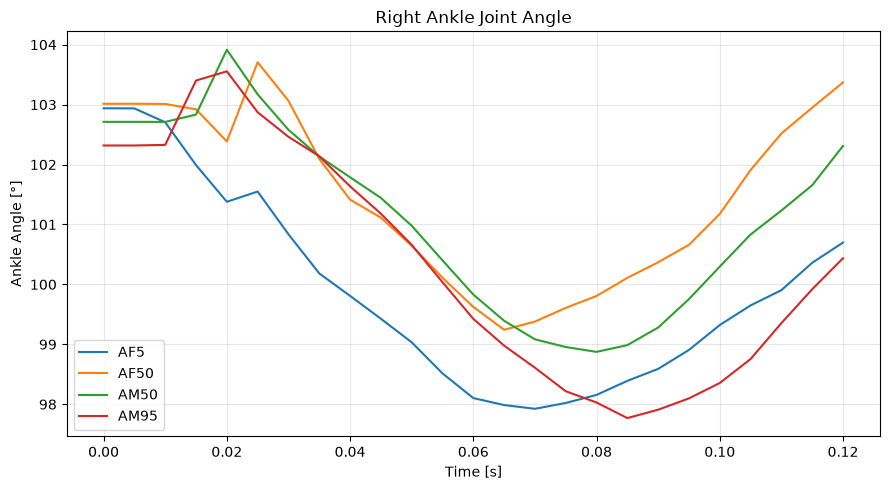

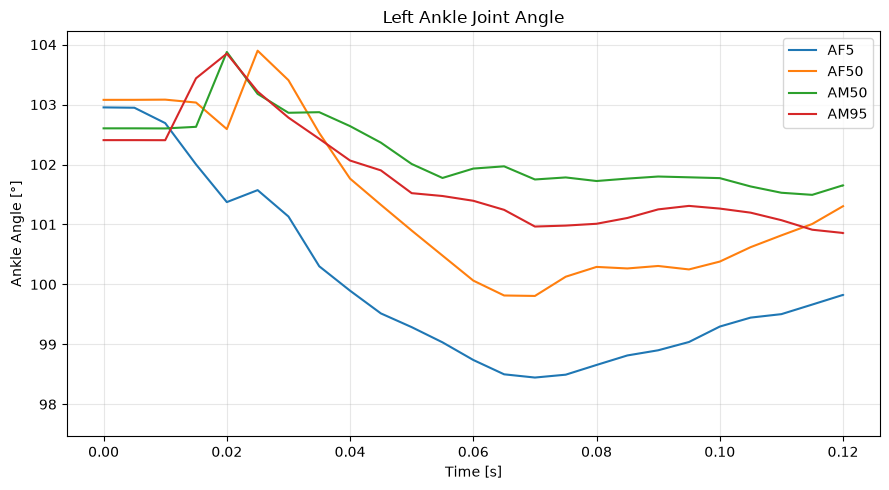

In [32]:
#Knoten Sprunggelenk

if log_level >= NORMAL:
    print("ankle-joint-angle right")

for model in models:
    (
        model.result_ankle_right,
        model.time_ankle_right,
        model.angle_ankle_right,
        model.delta_ankle_right
    ) = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["ankle_right"]["tibia"],
        model.CONFIG["nodes"]["ankle_right"]["ankle"],
        model.CONFIG["nodes"]["ankle_right"]["forefoot"],
        "Ankle angle right",
        model.d3plot
    )

    (
        model.result_ankle_left,
        model.time_ankle_left,
        model.angle_ankle_left,
        model.delta_ankle_left
    ) = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["ankle_left"]["tibia"],
        model.CONFIG["nodes"]["ankle_left"]["ankle"],
        model.CONFIG["nodes"]["ankle_left"]["forefoot"],
        "Ankle angle left",
        model.d3plot
    )
    
    if log_level >= NORMAL:
        print(model.NAME + ":\n")
        print(f"Initial angle:       {model.result_ankle_right['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.result_ankle_right['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.result_ankle_right['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.result_ankle_right['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.result_ankle_right['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.result_ankle_right['Max_Change_Time_s']:.4f} s")

        print()

        print("ankle-joint-angle left")
        print(f"Initial angle:       {model.result_ankle_left['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.result_ankle_left['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.result_ankle_left['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.result_ankle_left['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.result_ankle_left['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.result_ankle_left['Max_Change_Time_s']:.4f} s")

        print()

#Plot right
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_ankle_right,
        model.angle_ankle_right,
        label=model.NAME
    )

plt.xlabel("Time [s]")
plt.ylabel("Ankle Angle [°]")
plt.title("Right Ankle Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("angle_ankle_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_ankle_joint_angle.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

#Plot left
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_ankle_left,
        model.angle_ankle_left,
        label=model.NAME
    )

plt.xlabel("Time [s]")
plt.ylabel("Ankle Angle [°]")
plt.title("Left Ankle Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("angle_ankle_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_ankle_joint_angle.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

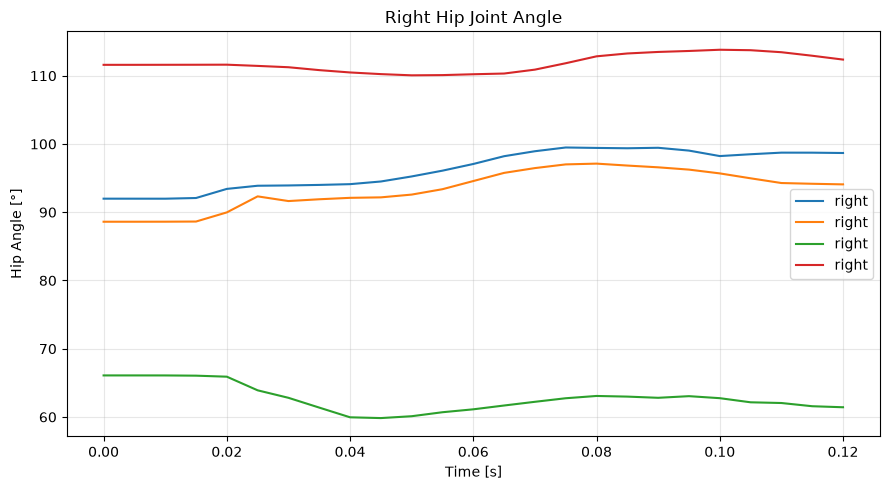

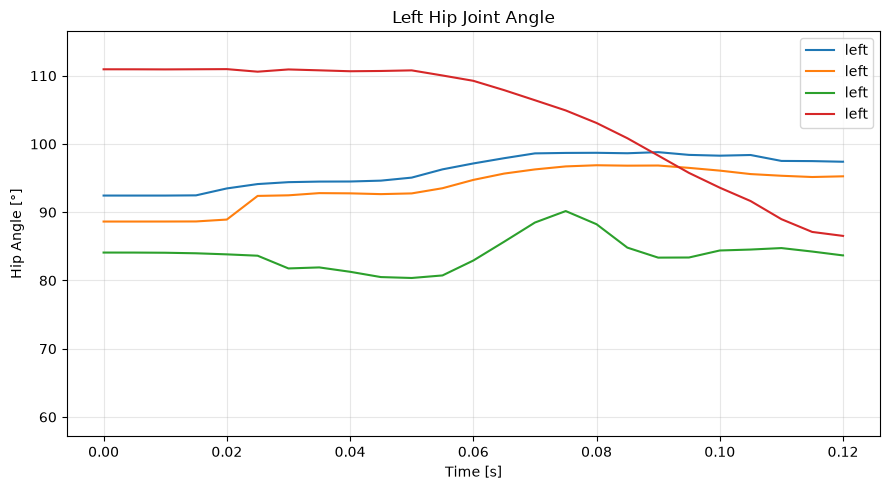

In [33]:
#Knoten Hüfte

if log_level >= NORMAL:
    print("Hip-angle right")
    
for model in models:
    (
        model.result_hip_right,
        model.time_hip_right,
        model.angle_hip_right,
        model.delta_hip_right
    ) = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["hip_right"]["pelvis"],
        model.CONFIG["nodes"]["hip_right"]["hip"],
        model.CONFIG["nodes"]["hip_right"]["femur"],
        "Hip angle right",
        model.d3plot
    )

    (
        model.result_hip_left,
        model.time_hip_left,
        model.angle_hip_left,
        model.delta_hip_left
    ) = calculate_joint_angle_3points(
        model.CONFIG["nodes"]["hip_left"]["pelvis"],
        model.CONFIG["nodes"]["hip_left"]["hip"],
        model.CONFIG["nodes"]["hip_left"]["femur"],
        "Hip angle left",
        model.d3plot
    )
    
    if log_level >= NORMAL:
        print(model.NAME + ":\n")
        print(f"Initial angle:       {model.result_hip_right['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.result_hip_right['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.result_hip_right['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.result_hip_right['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.result_hip_right['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.result_hip_right['Max_Change_Time_s']:.4f} s")

        print()

        print("Hip-angle left")
        print(f"Initial angle:       {model.result_hip_left['Initial_Angle_deg']:.2f} °")
        print(f"Minimum angle:       {model.result_hip_left['Min_Angle_deg']:.2f} °")
        print(f"Maximum angle:       {model.result_hip_left['Max_Angle_deg']:.2f} °")
        print(f"Max. angle change:   {model.result_hip_left['Max_Angle_Change_deg']:.2f} °")
        print(f"Angle at max change: {model.result_hip_left['Angle_at_Max_Change_deg']:.2f} °")
        print(f"Time:                {model.result_hip_left['Max_Change_Time_s']:.4f} s")

#Plot right
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_hip_right,
        model.angle_hip_right,
        label="right"
    )

plt.xlabel("Time [s]")
plt.ylabel("Hip Angle [°]")
plt.title("Right Hip Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("angle_hip_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "right_pelvis_angle.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

#Plot left
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(
        model.time_hip_left,
        model.angle_hip_left,
        label="left"
    )

plt.xlabel("Time [s]")
plt.ylabel("Hip Angle [°]")
plt.title("Left Hip Joint Angle")

plt.grid(True, alpha=0.3)
plt.legend()

set_common_ylim("angle_hip_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(
        OUTPUT_DIR / "left_pelvis_angle.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close()

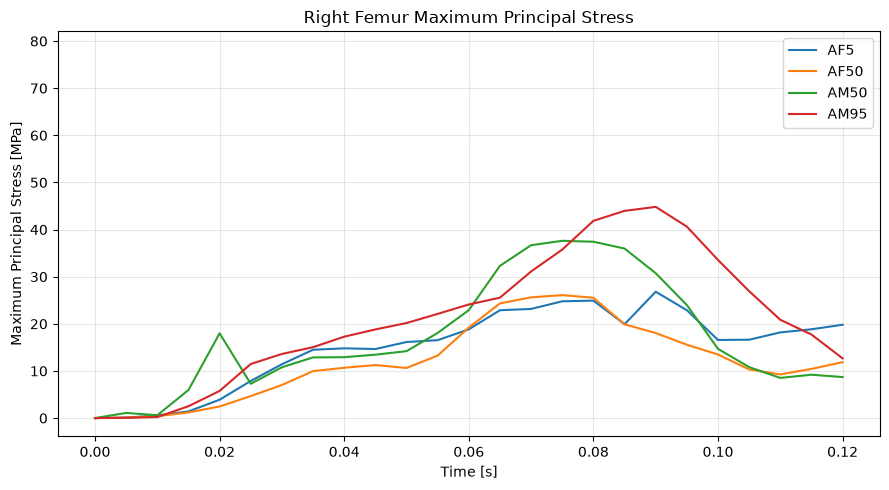

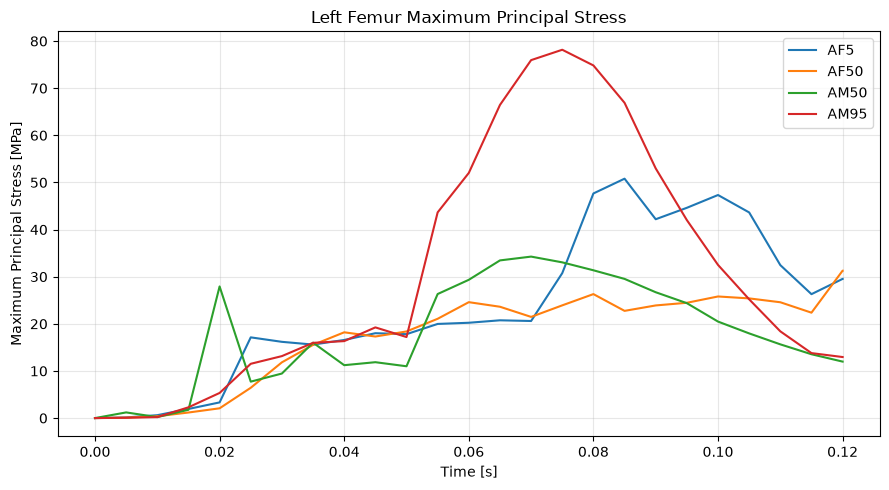

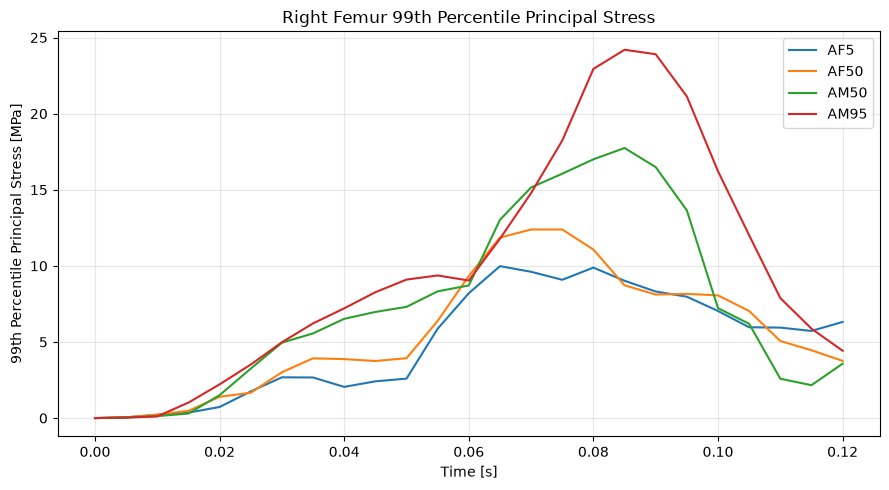

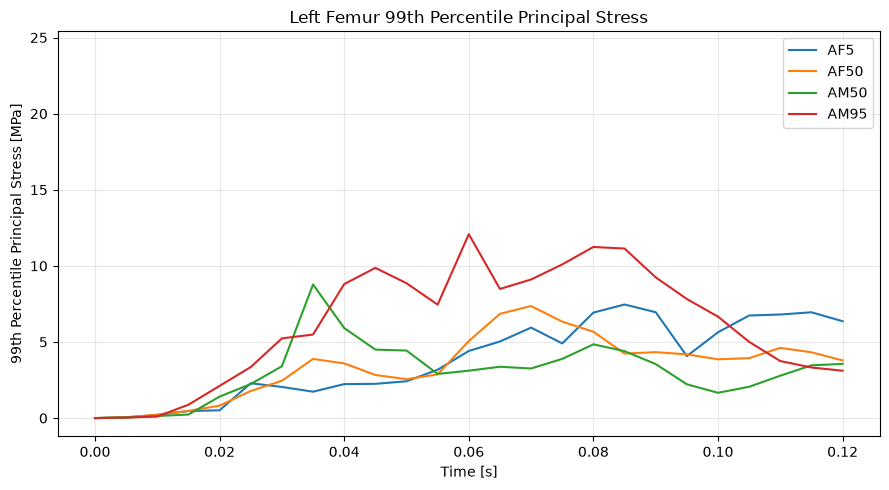

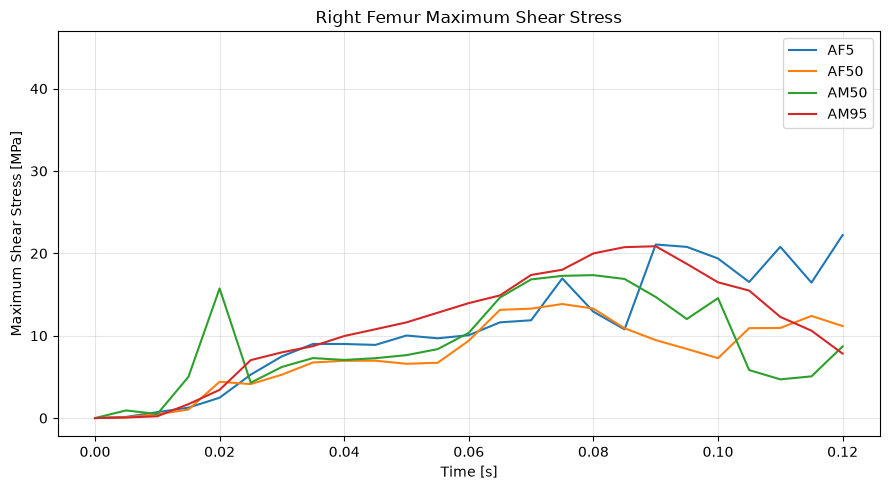

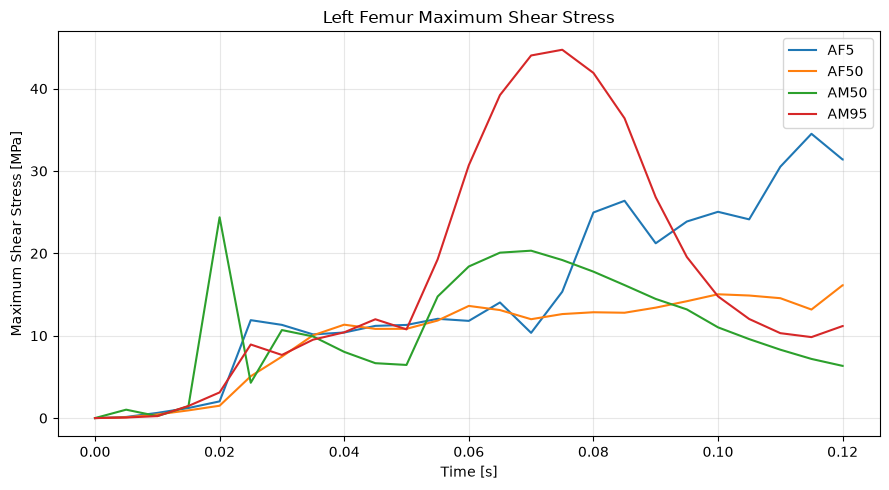

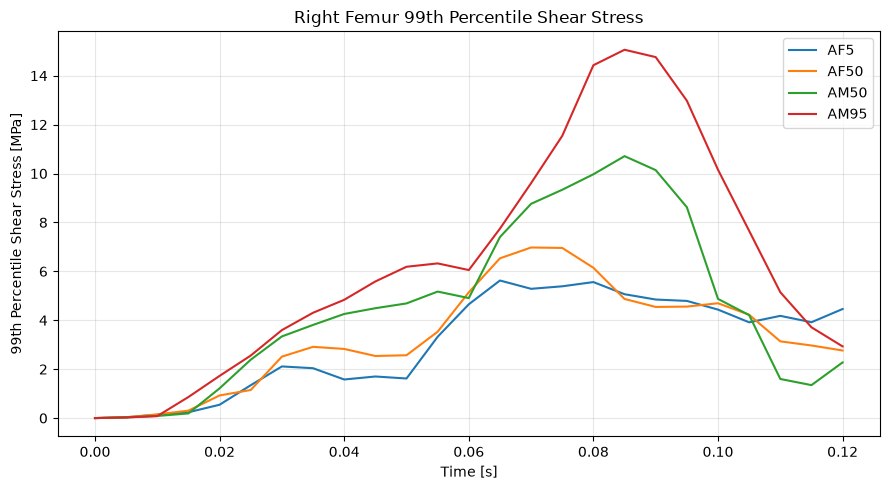

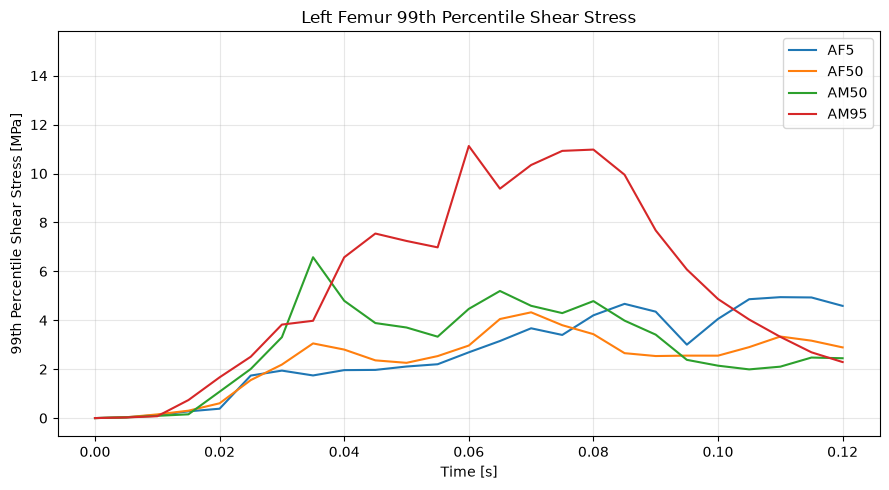

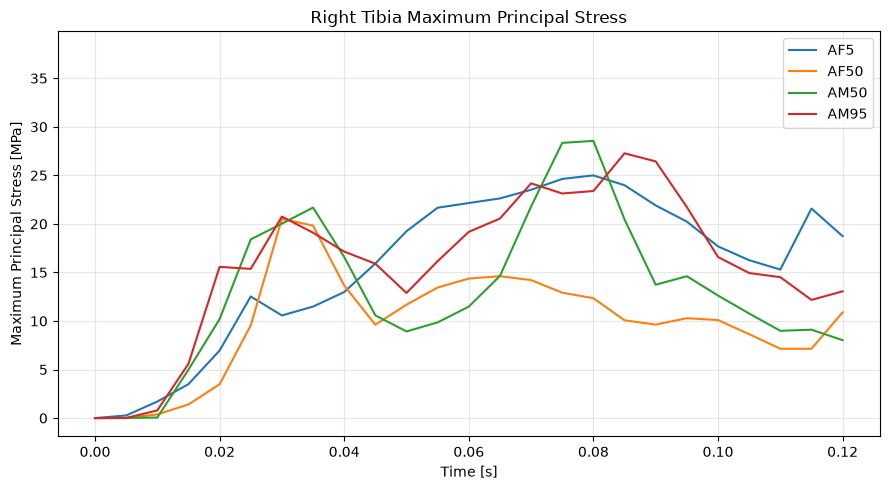

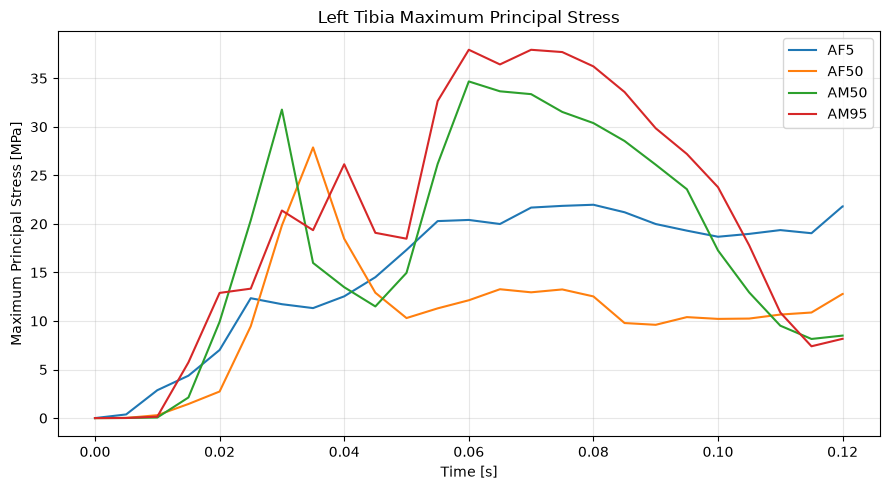

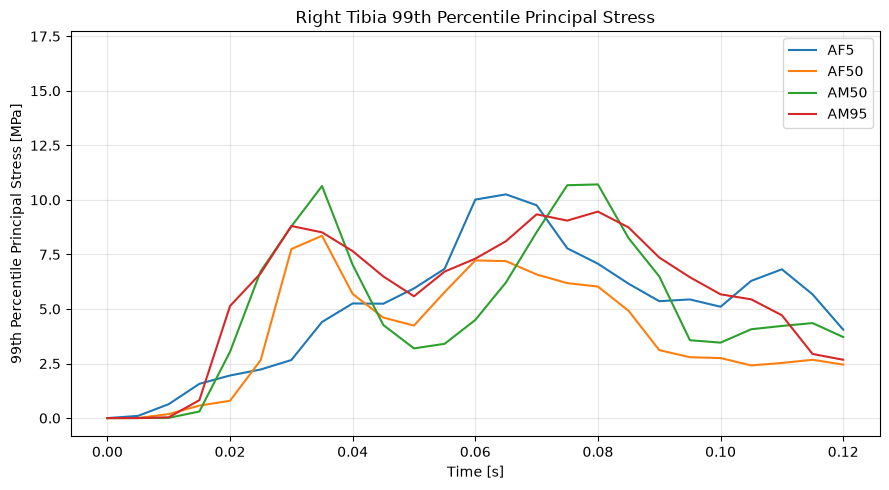

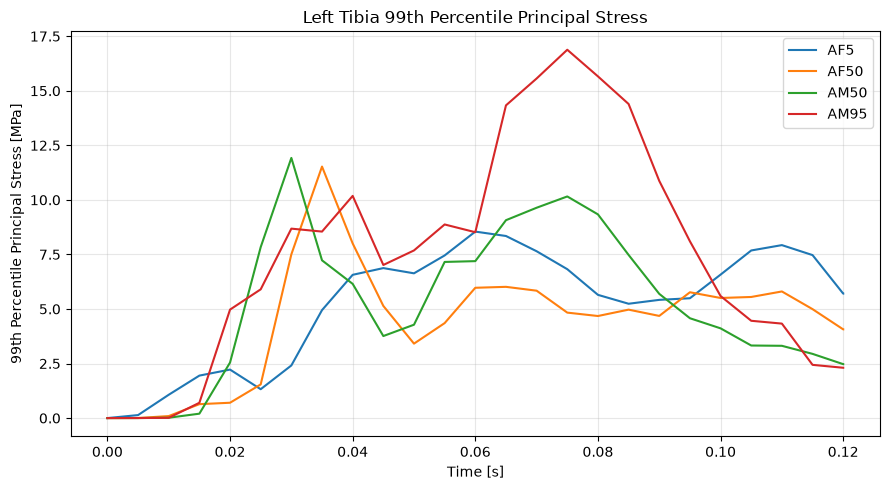

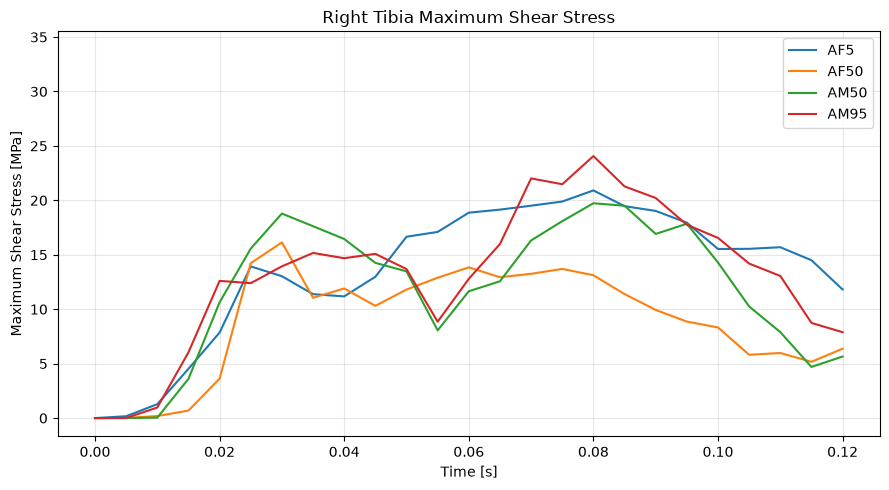

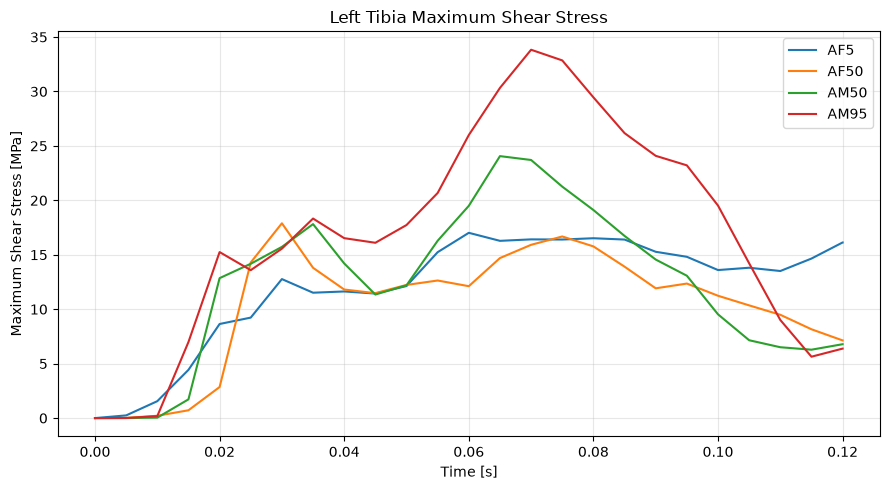

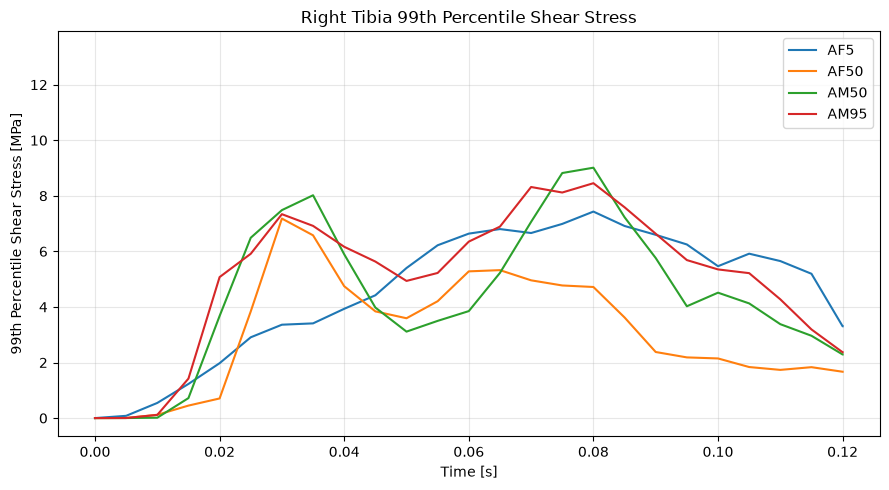

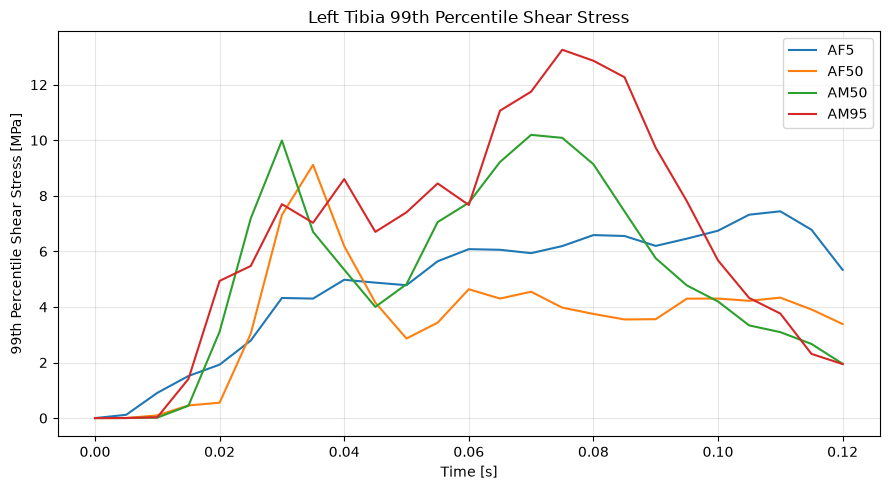

In [34]:
# Prinzipalspannung / Schubspannung / von Mises für Femur und Tibia + 99th percentile stress

from lasso.dyna import ArrayType


# Funktion
def evaluate_solid_part_stress(d3plot, wanted_part_ids, name):
    if len(wanted_part_ids) == 0:
        raise ValueError(f"Für {name} wurden keine Part-IDs angegeben.")

    # Part-Zuordnung
    part_ids = np.asarray(d3plot.arrays[ArrayType.part_ids])
    solid_part_indexes = np.asarray(d3plot.arrays[ArrayType.element_solid_part_indexes])
    solid_element_ids = np.asarray(d3plot.arrays[ArrayType.element_solid_ids])

    solid_part_ids = part_ids[solid_part_indexes]

    # gewünschte Elemente auswählen
    element_mask = np.isin(solid_part_ids, wanted_part_ids)

    if np.sum(element_mask) == 0:
        raise ValueError(f"Keine Solid-Elemente für {name} mit Part-IDs {wanted_part_ids} gefunden.")

    selected_element_ids = solid_element_ids[element_mask]

    # Stress-Array
    if ArrayType.element_solid_stress not in d3plot.arrays:
        raise ValueError("element_solid_stress ist im d3plot nicht vorhanden.")

    stress_all = np.asarray(d3plot.arrays[ArrayType.element_solid_stress])

    if log_level >= FULL:
        print()
        print(name)
        print("Stress array shape:", stress_all.shape)
        print("Anzahl Elemente:", np.sum(element_mask))
        print()

    # nur ausgewählte Parts
    stress = stress_all[:, element_mask, ...]

    # Letzte Dimension muss 6 Komponenten enthalten: xx, yy, zz, xy, yz, xz
    if stress.shape[-1] != 6:
        raise ValueError(
            f"Unerwartete Stress-Struktur: {stress.shape}. "
            "Die letzte Dimension sollte 6 Komponenten enthalten."
        )

    sxx = stress[..., 0]
    syy = stress[..., 1]
    szz = stress[..., 2]

    sxy = stress[..., 3]
    syz = stress[..., 4]
    sxz = stress[..., 5]

    # Spannungstensor
    tensor_shape = stress.shape[:-1] + (3, 3)
    stress_tensor = np.zeros(tensor_shape, dtype=float)

    stress_tensor[..., 0, 0] = sxx
    stress_tensor[..., 1, 1] = syy
    stress_tensor[..., 2, 2] = szz

    stress_tensor[..., 0, 1] = sxy
    stress_tensor[..., 1, 0] = sxy

    stress_tensor[..., 1, 2] = syz
    stress_tensor[..., 2, 1] = syz

    stress_tensor[..., 0, 2] = sxz
    stress_tensor[..., 2, 0] = sxz

    # Hauptspannung
    principal_stresses = np.linalg.eigvalsh(stress_tensor)

    sigma_min = principal_stresses[..., 0]
    sigma_mid = principal_stresses[..., 1]
    sigma_max = principal_stresses[..., 2]

    # Maximum Scherspannung: tau_max = (sigma_max - sigma_min) / 2
    max_shear = (sigma_max - sigma_min) / 2.0

    # von Mises
    von_mises = np.sqrt(
        0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2)
        + 3.0 * (sxy ** 2 + syz ** 2 + sxz ** 2)
    )

    # Maximalwert pro Zeitschritt über alle Elemente
    reduce_axes = tuple(range(1, sigma_max.ndim))

    max_principal_time = np.max(sigma_max, axis=reduce_axes)
    min_principal_time = np.min(sigma_min, axis=reduce_axes)
    max_shear_time = np.max(max_shear, axis=reduce_axes)
    von_mises_time = np.max(von_mises, axis=reduce_axes)

    # 99th percentile pro Zeitschritt über alle Elemente
    max_principal_p99_time = np.percentile(sigma_max, 99, axis=reduce_axes)
    max_shear_p99_time = np.percentile(max_shear, 99, axis=reduce_axes)
    von_mises_p99_time = np.percentile(von_mises, 99, axis=reduce_axes)

    # Zeitachse
    try:
        time = np.asarray(d3plot.arrays[ArrayType.global_timesteps])
    except Exception:
        time = get_d3plot_time(d3plot)

    # Hilfsfunktion für Maximum
    def find_global_max(data):
        flat_index = np.argmax(data)
        idx = np.unravel_index(flat_index, data.shape)

        state_idx = idx[0]
        element_idx = idx[1]

        value = data[idx]
        element_id = selected_element_ids[element_idx]

        return float(value), float(time[state_idx]), int(element_id)

    # Maximum Principal Stress
    max_principal_peak, max_principal_peak_time, max_principal_element = find_global_max(sigma_max)

    # Minimum Principal Stress
    flat_index = np.argmin(sigma_min)
    idx = np.unravel_index(flat_index, sigma_min.shape)

    state_idx = idx[0]
    element_idx = idx[1]

    min_principal_peak = float(sigma_min[idx])
    min_principal_peak_time = float(time[state_idx])
    min_principal_element = int(selected_element_ids[element_idx])

    # Maximum Shear
    max_shear_peak, max_shear_peak_time, max_shear_element = find_global_max(max_shear)

    # von Mises
    von_mises_peak, von_mises_peak_time, von_mises_element = find_global_max(von_mises)

    # 99th percentile Principal Stress Peak
    p99_principal_idx = np.argmax(max_principal_p99_time)
    p99_principal_peak = float(max_principal_p99_time[p99_principal_idx])
    p99_principal_peak_time = float(time[p99_principal_idx])

    # 99th percentile Shear Stress Peak
    p99_shear_idx = np.argmax(max_shear_p99_time)
    p99_shear_peak = float(max_shear_p99_time[p99_shear_idx])
    p99_shear_peak_time = float(time[p99_shear_idx])

    # 99th percentile von Mises Stress Peak
    p99_vm_idx = np.argmax(von_mises_p99_time)
    p99_vm_peak = float(von_mises_p99_time[p99_vm_idx])
    p99_vm_peak_time = float(time[p99_vm_idx])

    result = {
        "name": name,

        "Max_Principal_Stress": max_principal_peak,
        "Max_Principal_Time": max_principal_peak_time,
        "Max_Principal_Element": max_principal_element,

        "Max_Principal_P99": p99_principal_peak,
        "Max_Principal_P99_Time": p99_principal_peak_time,

        "Min_Principal_Stress": min_principal_peak,
        "Min_Principal_Time": min_principal_peak_time,
        "Min_Principal_Element": min_principal_element,

        "Max_Shear_Stress": max_shear_peak,
        "Max_Shear_Time": max_shear_peak_time,
        "Max_Shear_Element": max_shear_element,

        "Max_Shear_P99": p99_shear_peak,
        "Max_Shear_P99_Time": p99_shear_peak_time,

        "Von_Mises_Stress": von_mises_peak,
        "Von_Mises_Time": von_mises_peak_time,
        "Von_Mises_Element": von_mises_element,

        "Von_Mises_P99": p99_vm_peak,
        "Von_Mises_P99_Time": p99_vm_peak_time,

        "Number_elements": int(np.sum(element_mask)),
    }

    return (
        result,
        time,
        max_principal_time,
        min_principal_time,
        max_shear_time,
        von_mises_time,
        max_principal_p99_time,
        max_shear_p99_time,
        von_mises_p99_time,
    )

# Ergebnisse ausgeben
def print_stress_result(result):
    print(result["name"])

    print(f"Maximum principal stress: {result['Max_Principal_Stress']:.3f} MPa")
    print(f"  Time:    {result['Max_Principal_Time']:.4f} s")
    print(f"  Element: {result['Max_Principal_Element']}")

    print(f"99th percentile principal stress: {result['Max_Principal_P99']:.3f} MPa")
    print(f"  Time:    {result['Max_Principal_P99_Time']:.4f} s")

    print(f"Minimum principal stress: {result['Min_Principal_Stress']:.3f} MPa")
    print(f"  Time:    {result['Min_Principal_Time']:.4f} s")
    print(f"  Element: {result['Min_Principal_Element']}")

    print(f"Maximum shear stress: {result['Max_Shear_Stress']:.3f} MPa")
    print(f"  Time:    {result['Max_Shear_Time']:.4f} s")
    print(f"  Element: {result['Max_Shear_Element']}")

    print(f"99th percentile shear stress: {result['Max_Shear_P99']:.3f} MPa")
    print(f"  Time:    {result['Max_Shear_P99_Time']:.4f} s")

    print(f"von Mises stress: {result['Von_Mises_Stress']:.3f} MPa")
    print(f"  Time:    {result['Von_Mises_Time']:.4f} s")
    print(f"  Element: {result['Von_Mises_Element']}")

    print(f"99th percentile von Mises stress: {result['Von_Mises_P99']:.3f} MPa")
    print(f"  Time:    {result['Von_Mises_P99_Time']:.4f} s")

    print()

for model in models:
    # Femur
    (model.stress_femur_left, model.time_femur_left, model.max_principal_femur_left, model.min_principal_femur_left, model.shear_femur_left, model.von_mises_femur_left, model.p99_principal_femur_left, model.p99_shear_femur_left, model.p99_vm_femur_left) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["femur_left"], "Femur left"
    )

    (model.stress_femur_right, model.time_femur_right, model.max_principal_femur_right, model.min_principal_femur_right, model.shear_femur_right, model.von_mises_femur_right, model.p99_principal_femur_right, model.p99_shear_femur_right, model.p99_vm_femur_right) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["femur_right"], "Femur right"
    )

    # Tibia
    (model.stress_tibia_left, model.time_tibia_left, model.max_principal_tibia_left, model.min_principal_tibia_left, model.shear_tibia_left, model.von_mises_tibia_left, model.p99_principal_tibia_left, model.p99_shear_tibia_left, model.p99_vm_tibia_left) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["tibia_left"], "Tibia left"
    )

    (model.stress_tibia_right, model.time_tibia_right, model.max_principal_tibia_right, model.min_principal_tibia_right, model.shear_tibia_right, model.von_mises_tibia_right, model.p99_principal_tibia_right, model.p99_shear_tibia_right, model.p99_vm_tibia_right) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["tibia_right"], "Tibia right"
    )
    
    if log_level >= NORMAL:
        print_stress_result(model.stress_femur_left)
        print_stress_result(model.stress_femur_right)
        print_stress_result(model.stress_tibia_left)
        print_stress_result(model.stress_tibia_right)


# Femur – Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.max_principal_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Right Femur Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_femur_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Femur_max_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

# Femur – Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.max_principal_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Left Femur Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_femur_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Femur_max_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur – 99th percentile principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.p99_principal_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Right Femur 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_femur_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Femur_p99_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.p99_principal_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Left Femur 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_femur_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Femur_p99_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur - Maximum shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.shear_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Right Femur Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_femur_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Femur_max_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.shear_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Left Femur Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_femur_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Femur_max_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur - 99th percentile shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.p99_shear_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Right Femur 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_femur_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Femur_p99_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.p99_shear_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Left Femur 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_femur_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Femur_p99_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.max_principal_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Right Tibia Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_tibia_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_max_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.max_principal_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Left Tibia Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_tibia_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_max_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - 99th percentile principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.p99_principal_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Right Tibia 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_tibia_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_p99_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.p99_principal_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Left Tibia 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_tibia_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_p99_principal_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - Maximum shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.shear_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Right Tibia Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_tibia_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_max_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.shear_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Left Tibia Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_tibia_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_max_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - 99th percentile shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.p99_shear_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Right Tibia 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_tibia_right")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_p99_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.p99_shear_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Left Tibia 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_tibia_left")
plt.tight_layout()

if log_level >= FULL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_p99_shear_stress.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

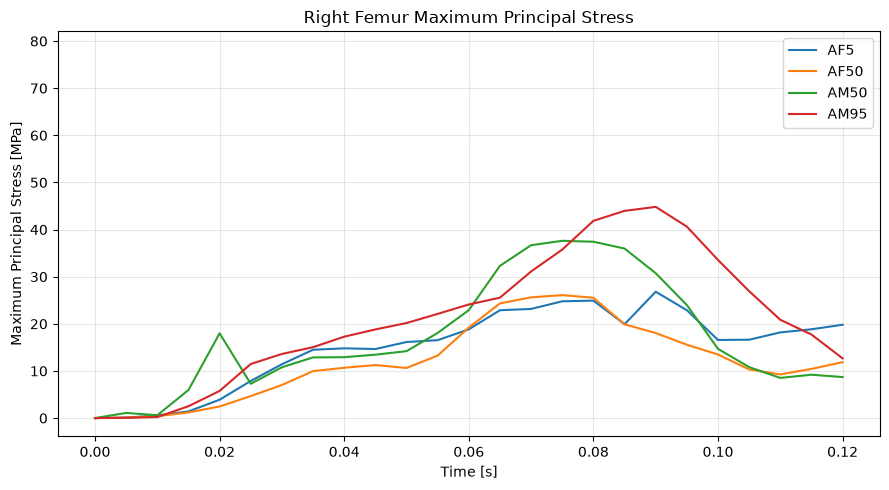

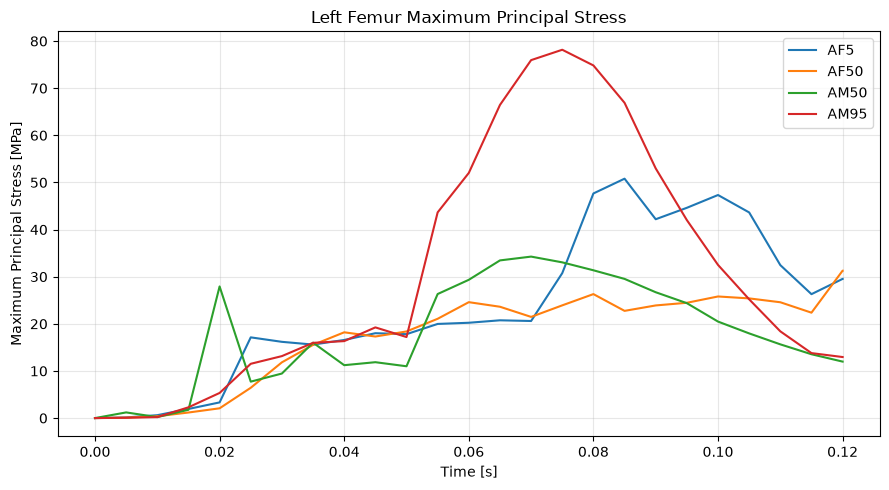

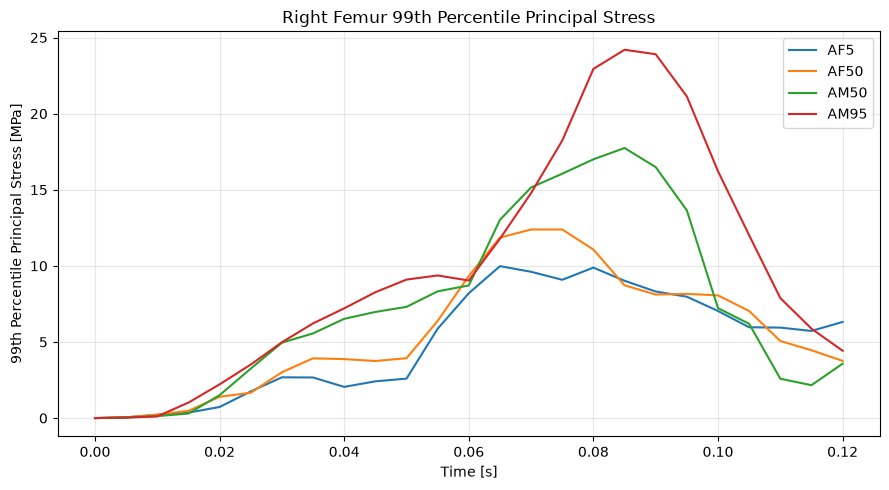

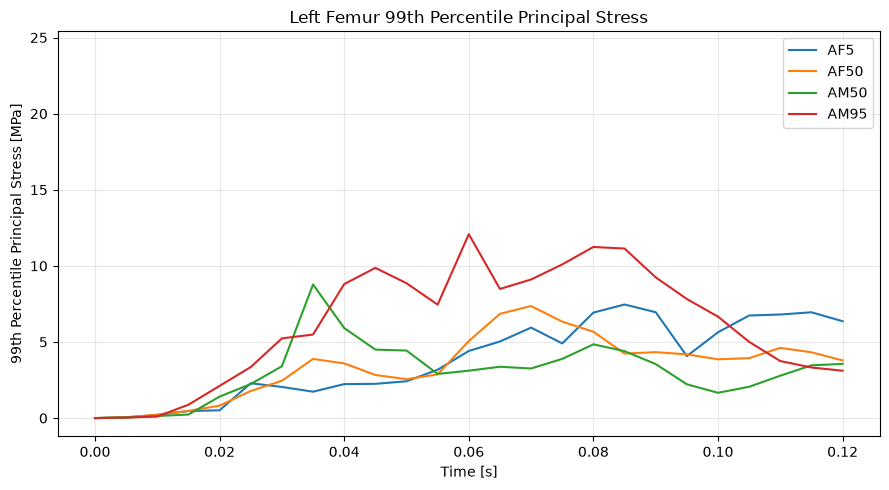

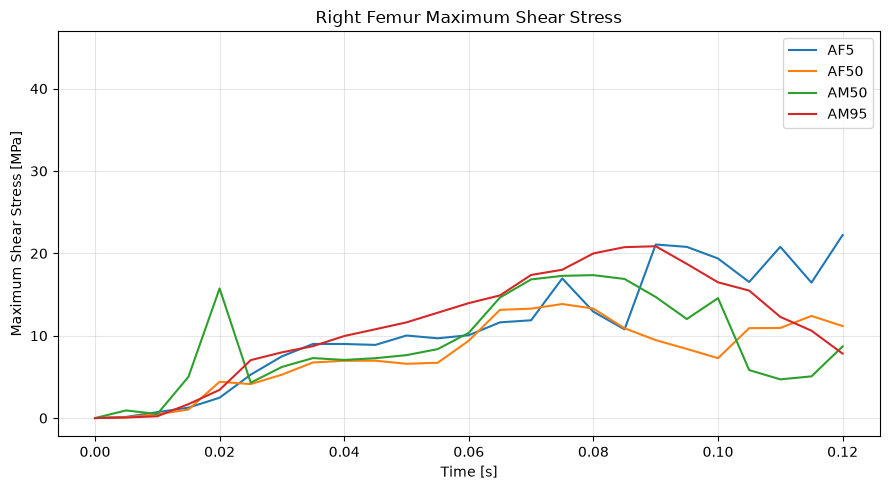

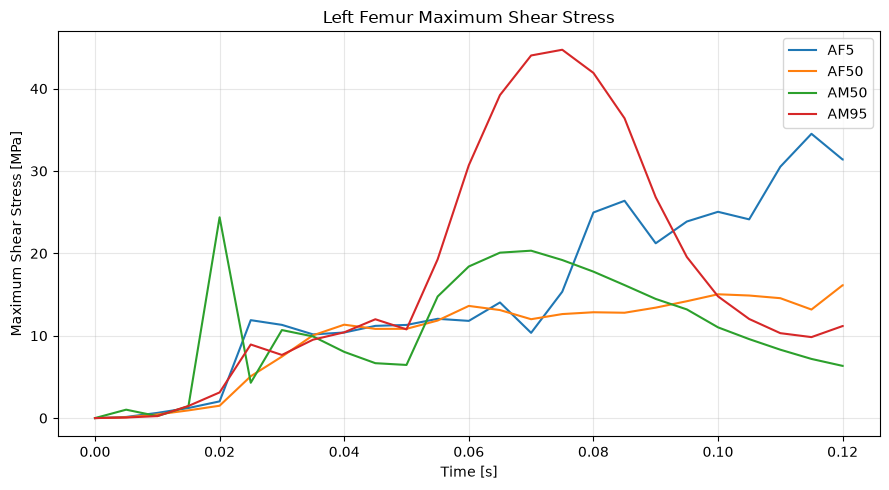

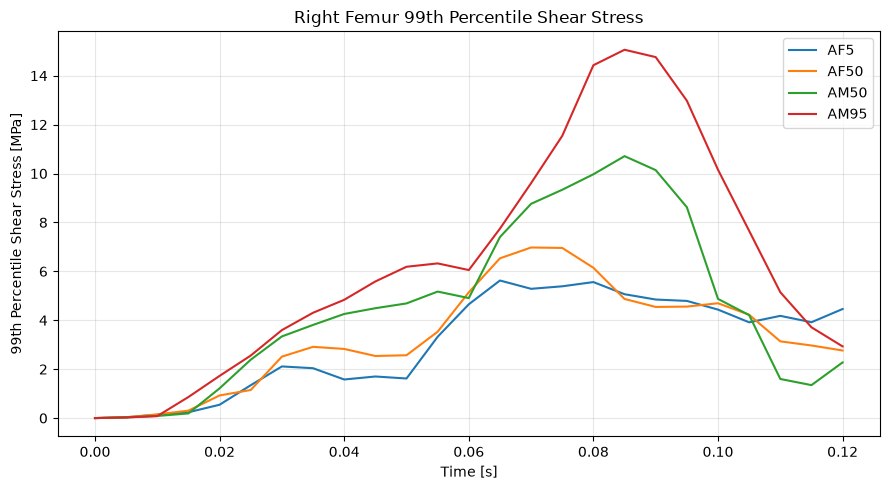

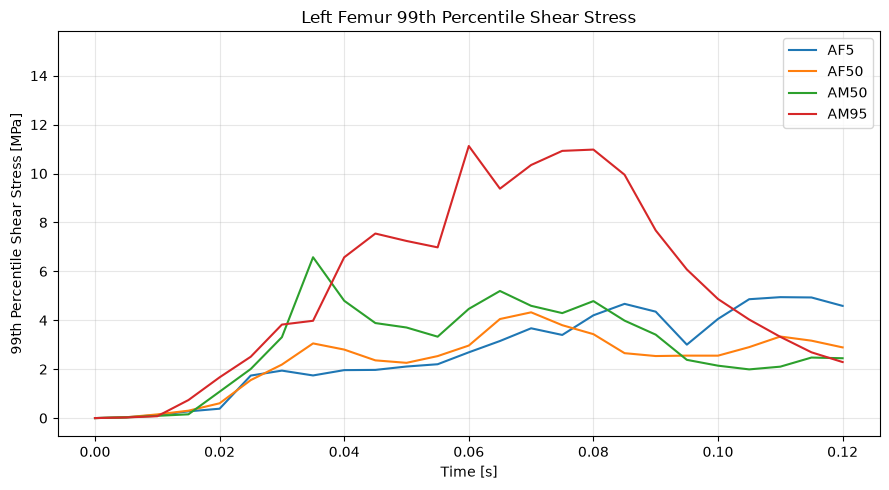

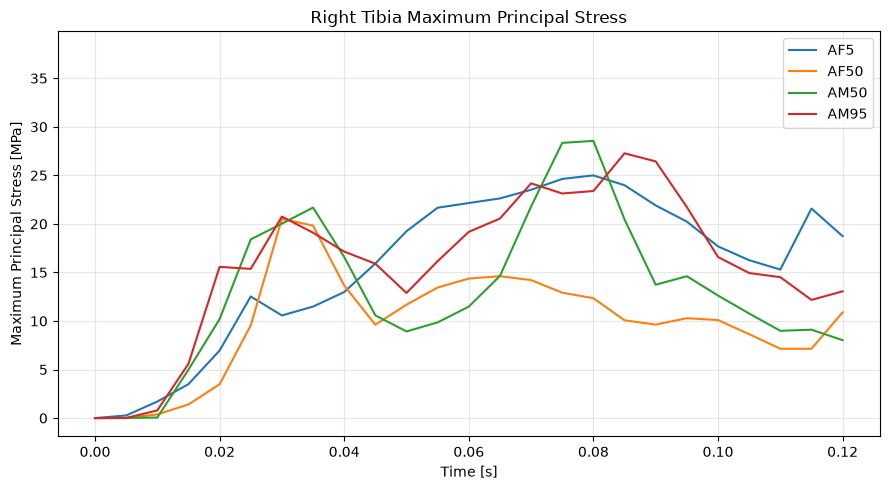

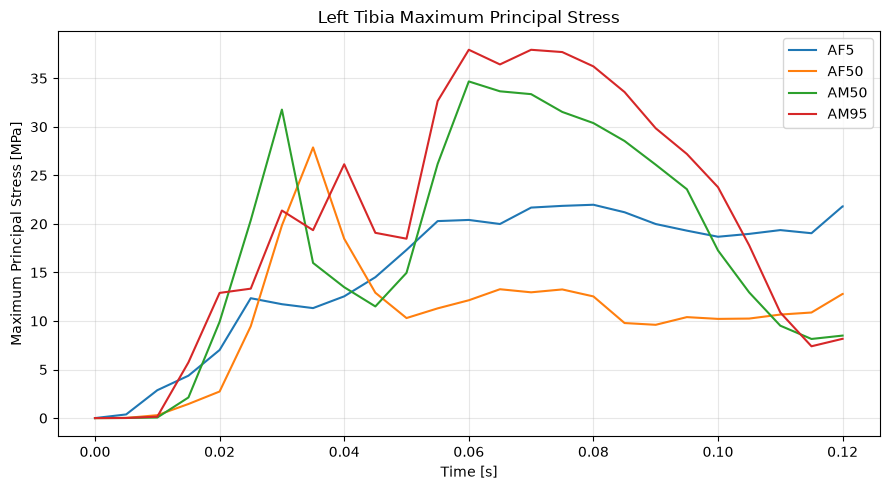

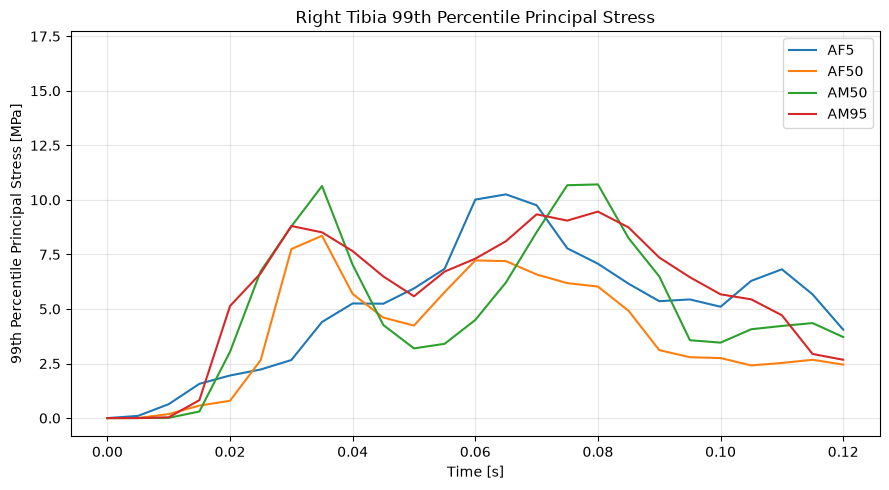

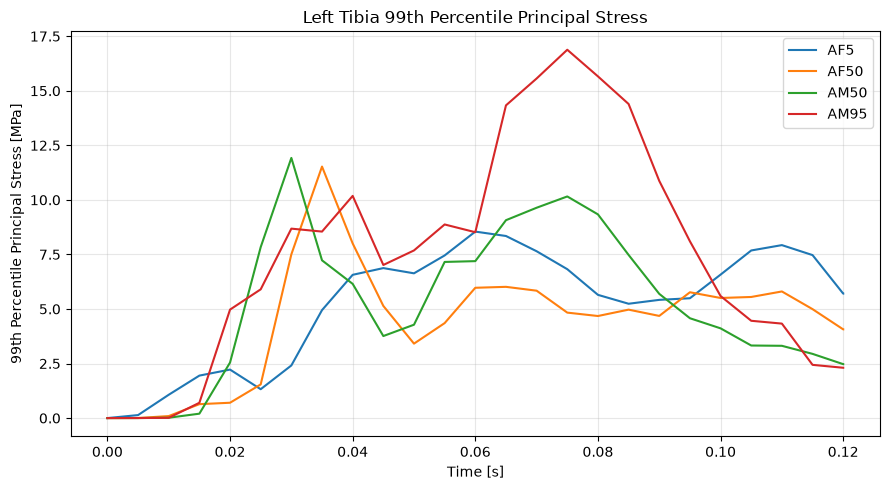

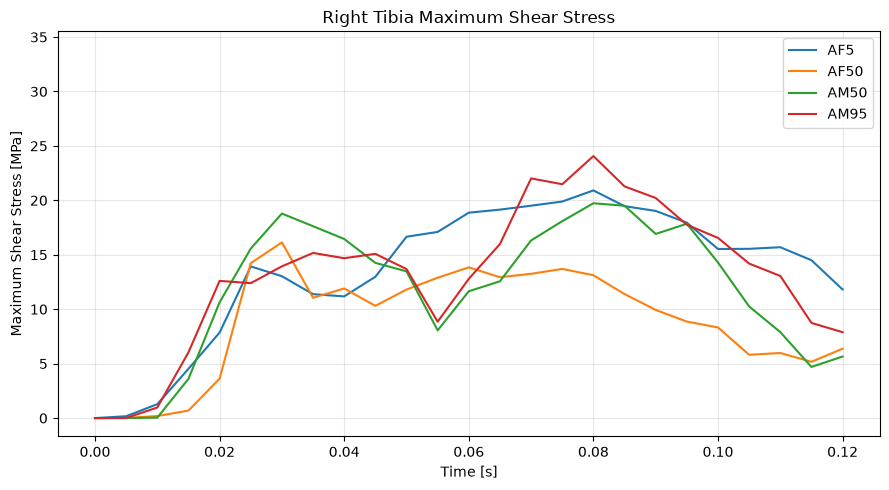

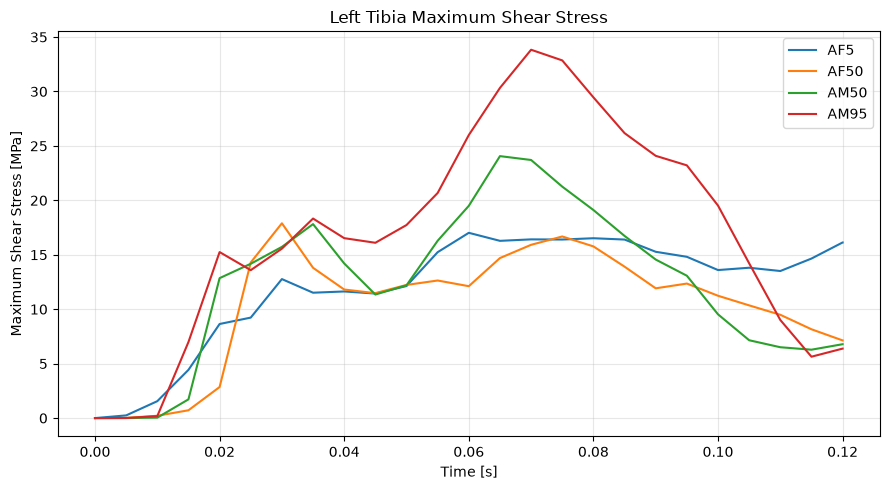

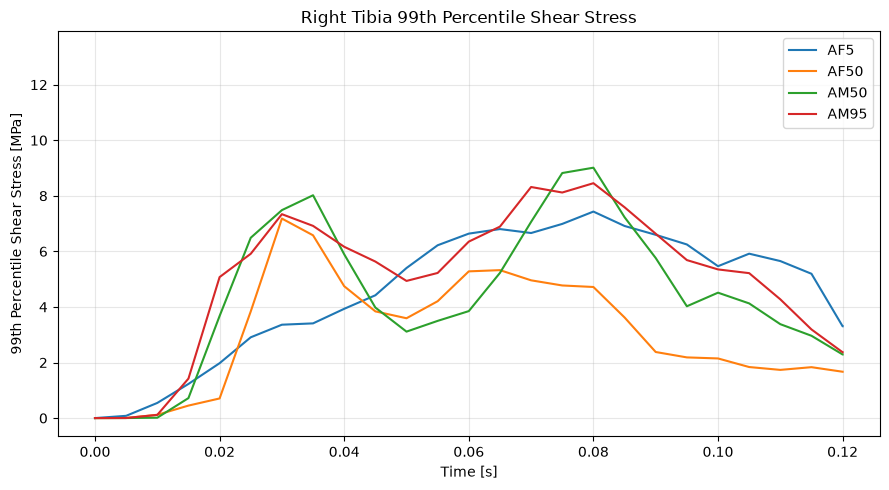

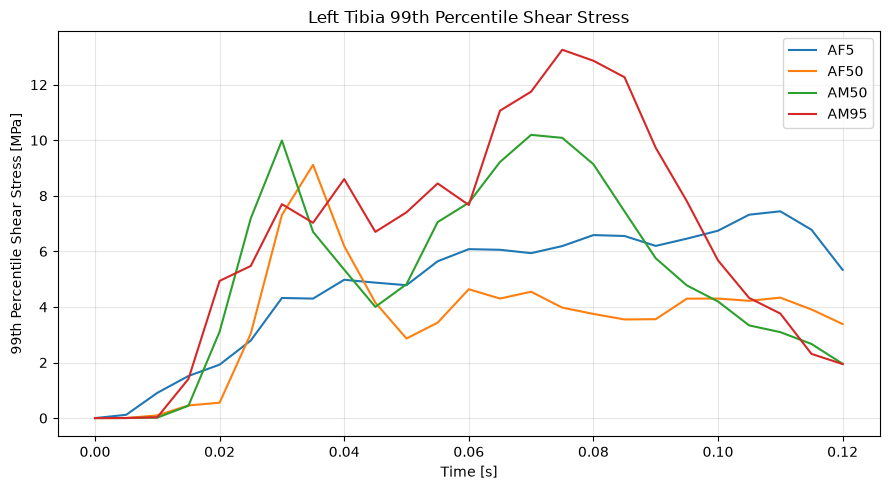

In [35]:
# Principal stress / shear stress / von Mises für Femur und Tibia + 99th percentile stress (Filtered)

from lasso.dyna import ArrayType
import numpy as np
import matplotlib.pyplot as plt

# Cutoff-Frequenz für den Filter
# CUTOFF_HZ = 50.0


# Funktion
def evaluate_solid_part_stress_filtered(d3plot, wanted_part_ids, name, cutoff_hz=CUTOFF_HZ):
    if len(wanted_part_ids) == 0:
        raise ValueError(f"Für {name} wurden keine Part-IDs angegeben.")

    # Zeitachse (wird früh benötigt für den Filter)
    try:
        time = np.asarray(d3plot.arrays[ArrayType.global_timesteps])
    except Exception:
        time = get_d3plot_time(d3plot)

    # Part-Zuordnung
    part_ids = np.asarray(d3plot.arrays[ArrayType.part_ids])
    solid_part_indexes = np.asarray(d3plot.arrays[ArrayType.element_solid_part_indexes])
    solid_element_ids = np.asarray(d3plot.arrays[ArrayType.element_solid_ids])

    solid_part_ids = part_ids[solid_part_indexes]

    # gewünschte Elemente auswählen
    element_mask = np.isin(solid_part_ids, wanted_part_ids)

    if np.sum(element_mask) == 0:
        raise ValueError(f"Keine Solid-Elemente für {name} mit Part-IDs {wanted_part_ids} gefunden.")

    selected_element_ids = solid_element_ids[element_mask]

    # Stress-Array
    if ArrayType.element_solid_stress not in d3plot.arrays:
        raise ValueError("element_solid_stress ist im d3plot nicht vorhanden.")

    stress_all = np.asarray(d3plot.arrays[ArrayType.element_solid_stress])

    if log_level >= FULL:
        print()
        print(f"{name} (Filtered at {cutoff_hz} Hz)")
        print("Stress array shape:", stress_all.shape)
        print("Anzahl Elemente:", np.sum(element_mask))
        print()

    # nur ausgewählte Parts
    stress = stress_all[:, element_mask, ...]

    # Letzte Dimension muss 6 Komponenten enthalten: xx, yy, zz, xy, yz, xz
    if stress.shape[-1] != 6:
        raise ValueError(
            f"Unerwartete Stress-Struktur: {stress.shape}. "
            "Die letzte Dimension sollte 6 Komponenten enthalten."
        )

    # Hilfsfunktion zum Filtern der einzelnen Komponenten
    # Die Zeitachse (0) wird temporär nach hinten geschoben für den Filter
    def filter_component(comp):
        comp_t = np.moveaxis(comp, 0, -1)
        comp_t_filt = lowpass_filter(time, comp_t)
        return np.moveaxis(comp_t_filt, -1, 0)

    # Komponenten auslesen und direkt filtern
    sxx = filter_component(stress[..., 0])
    syy = filter_component(stress[..., 1])
    szz = filter_component(stress[..., 2])

    sxy = filter_component(stress[..., 3])
    syz = filter_component(stress[..., 4])
    sxz = filter_component(stress[..., 5])

    # Spannungstensor
    tensor_shape = stress.shape[:-1] + (3, 3)
    stress_tensor = np.zeros(tensor_shape, dtype=float)

    stress_tensor[..., 0, 0] = sxx
    stress_tensor[..., 1, 1] = syy
    stress_tensor[..., 2, 2] = szz

    stress_tensor[..., 0, 1] = sxy
    stress_tensor[..., 1, 0] = sxy

    stress_tensor[..., 1, 2] = syz
    stress_tensor[..., 2, 1] = syz

    stress_tensor[..., 0, 2] = sxz
    stress_tensor[..., 2, 0] = sxz

    # Hauptspannung
    principal_stresses = np.linalg.eigvalsh(stress_tensor)

    sigma_min = principal_stresses[..., 0]
    sigma_mid = principal_stresses[..., 1]
    sigma_max = principal_stresses[..., 2]

    # Maximum Scherspannung: tau_max = (sigma_max - sigma_min) / 2
    max_shear = (sigma_max - sigma_min) / 2.0

    # von Mises
    von_mises = np.sqrt(
        0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2)
        + 3.0 * (sxy ** 2 + syz ** 2 + sxz ** 2)
    )

    # Maximalwert pro Zeitschritt über alle Elemente
    reduce_axes = tuple(range(1, sigma_max.ndim))

    max_principal_time = np.max(sigma_max, axis=reduce_axes)
    min_principal_time = np.min(sigma_min, axis=reduce_axes)
    max_shear_time = np.max(max_shear, axis=reduce_axes)
    von_mises_time = np.max(von_mises, axis=reduce_axes)

    # 99th percentile pro Zeitschritt über alle Elemente
    max_principal_p99_time = np.percentile(sigma_max, 99, axis=reduce_axes)
    max_shear_p99_time = np.percentile(max_shear, 99, axis=reduce_axes)
    von_mises_p99_time = np.percentile(von_mises, 99, axis=reduce_axes)

    # Hilfsfunktion für Maximum
    def find_global_max(data):
        flat_index = np.argmax(data)
        idx = np.unravel_index(flat_index, data.shape)

        state_idx = idx[0]
        element_idx = idx[1]

        value = data[idx]
        element_id = selected_element_ids[element_idx]

        return float(value), float(time[state_idx]), int(element_id)

    # Maximum Principal Stress
    max_principal_peak, max_principal_peak_time, max_principal_element = find_global_max(sigma_max)

    # Minimum Principal Stress
    flat_index = np.argmin(sigma_min)
    idx = np.unravel_index(flat_index, sigma_min.shape)

    state_idx = idx[0]
    element_idx = idx[1]

    min_principal_peak = float(sigma_min[idx])
    min_principal_peak_time = float(time[state_idx])
    min_principal_element = int(selected_element_ids[element_idx])

    # Maximum Shear
    max_shear_peak, max_shear_peak_time, max_shear_element = find_global_max(max_shear)

    # von Mises
    von_mises_peak, von_mises_peak_time, von_mises_element = find_global_max(von_mises)

    # 99th percentile Principal Stress Peak
    p99_principal_idx = np.argmax(max_principal_p99_time)
    p99_principal_peak = float(max_principal_p99_time[p99_principal_idx])
    p99_principal_peak_time = float(time[p99_principal_idx])

    # 99th percentile Shear Stress Peak
    p99_shear_idx = np.argmax(max_shear_p99_time)
    p99_shear_peak = float(max_shear_p99_time[p99_shear_idx])
    p99_shear_peak_time = float(time[p99_shear_idx])

    # 99th percentile von Mises Stress Peak
    p99_vm_idx = np.argmax(von_mises_p99_time)
    p99_vm_peak = float(von_mises_p99_time[p99_vm_idx])
    p99_vm_peak_time = float(time[p99_vm_idx])

    result = {
        "name": name,

        "Max_Principal_Stress": max_principal_peak,
        "Max_Principal_Time": max_principal_peak_time,
        "Max_Principal_Element": max_principal_element,

        "Max_Principal_P99": p99_principal_peak,
        "Max_Principal_P99_Time": p99_principal_peak_time,

        "Min_Principal_Stress": min_principal_peak,
        "Min_Principal_Time": min_principal_peak_time,
        "Min_Principal_Element": min_principal_element,

        "Max_Shear_Stress": max_shear_peak,
        "Max_Shear_Time": max_shear_peak_time,
        "Max_Shear_Element": max_shear_element,

        "Max_Shear_P99": p99_shear_peak,
        "Max_Shear_P99_Time": p99_shear_peak_time,

        "Von_Mises_Stress": von_mises_peak,
        "Von_Mises_Time": von_mises_peak_time,
        "Von_Mises_Element": von_mises_element,

        "Von_Mises_P99": p99_vm_peak,
        "Von_Mises_P99_Time": p99_vm_peak_time,

        "Number_elements": int(np.sum(element_mask)),
    }

    return (
        result,
        time,
        max_principal_time,
        min_principal_time,
        max_shear_time,
        von_mises_time,
        max_principal_p99_time,
        max_shear_p99_time,
        von_mises_p99_time,
    )

# Ergebnisse ausgeben
def print_stress_result_filtered(result):
    print(result["name"])

    print(f"Maximum principal stress: {result['Max_Principal_Stress']:.3f} MPa")
    print(f"  Time:    {result['Max_Principal_Time']:.4f} s")
    print(f"  Element: {result['Max_Principal_Element']}")

    print(f"99th percentile principal stress: {result['Max_Principal_P99']:.3f} MPa")
    print(f"  Time:    {result['Max_Principal_P99_Time']:.4f} s")

    print(f"Minimum principal stress: {result['Min_Principal_Stress']:.3f} MPa")
    print(f"  Time:    {result['Min_Principal_Time']:.4f} s")
    print(f"  Element: {result['Min_Principal_Element']}")

    print(f"Maximum shear stress: {result['Max_Shear_Stress']:.3f} MPa")
    print(f"  Time:    {result['Max_Shear_Time']:.4f} s")
    print(f"  Element: {result['Max_Shear_Element']}")

    print(f"99th percentile shear stress: {result['Max_Shear_P99']:.3f} MPa")
    print(f"  Time:    {result['Max_Shear_P99_Time']:.4f} s")

    print(f"von Mises stress: {result['Von_Mises_Stress']:.3f} MPa")
    print(f"  Time:    {result['Von_Mises_Time']:.4f} s")
    print(f"  Element: {result['Von_Mises_Element']}")

    print(f"99th percentile von Mises stress: {result['Von_Mises_P99']:.3f} MPa")
    print(f"  Time:    {result['Von_Mises_P99_Time']:.4f} s")

    print()


for model in models:
    # Femur
    (model.stress_femur_left, model.time_femur_left, model.max_principal_femur_left, model.min_principal_femur_left, model.shear_femur_left, model.von_mises_femur_left, model.p99_principal_femur_left, model.p99_shear_femur_left, model.p99_vm_femur_left) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["femur_left"], "Femur left"
    )

    (model.stress_femur_right, model.time_femur_right, model.max_principal_femur_right, model.min_principal_femur_right, model.shear_femur_right, model.von_mises_femur_right, model.p99_principal_femur_right, model.p99_shear_femur_right, model.p99_vm_femur_right) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["femur_right"], "Femur right"
    )

    # Tibia
    (model.stress_tibia_left, model.time_tibia_left, model.max_principal_tibia_left, model.min_principal_tibia_left, model.shear_tibia_left, model.von_mises_tibia_left, model.p99_principal_tibia_left, model.p99_shear_tibia_left, model.p99_vm_tibia_left) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["tibia_left"], "Tibia left"
    )

    (model.stress_tibia_right, model.time_tibia_right, model.max_principal_tibia_right, model.min_principal_tibia_right, model.shear_tibia_right, model.von_mises_tibia_right, model.p99_principal_tibia_right, model.p99_shear_tibia_right, model.p99_vm_tibia_right) = evaluate_solid_part_stress(
        model.d3plot, model.CONFIG["parts"]["tibia_right"], "Tibia right"
    )
    
    if log_level >= NORMAL:
        print_stress_result(model.stress_femur_left)
        print_stress_result(model.stress_femur_right)
        print_stress_result(model.stress_tibia_left)
        print_stress_result(model.stress_tibia_right)


# Femur – Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.max_principal_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Right Femur Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_femur_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Femur_max_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

# Femur – Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.max_principal_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Left Femur Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_femur_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Femur_max_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur – 99th percentile principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.p99_principal_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Right Femur 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_femur_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Femur_p99_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.p99_principal_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Left Femur 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_femur_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Femur_p99_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur - Maximum shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.shear_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Right Femur Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_femur_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Femur_max_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.shear_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Left Femur Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_femur_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Femur_max_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Femur - 99th percentile shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_right, model.p99_shear_femur_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Right Femur 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_femur_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Femur_p99_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_femur_left, model.p99_shear_femur_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Left Femur 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_femur_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Femur_p99_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - Maximum principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.max_principal_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Right Tibia Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_tibia_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_max_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.max_principal_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Principal Stress [MPa]")
plt.title("Left Tibia Maximum Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("max_principal_tibia_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_max_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - 99th percentile principal stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.p99_principal_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Right Tibia 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_tibia_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_p99_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.p99_principal_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Principal Stress [MPa]")
plt.title("Left Tibia 99th Percentile Principal Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_principal_tibia_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_p99_principal_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - Maximum shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.shear_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Right Tibia Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_tibia_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_max_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.shear_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("Maximum Shear Stress [MPa]")
plt.title("Left Tibia Maximum Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("shear_tibia_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_max_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()


# Tibia - 99th percentile shear stress
plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_right, model.p99_shear_tibia_right, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Right Tibia 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_tibia_right")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "right_Tibia_p99_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

plt.figure(figsize=(9, 5))

for model in models:
    plt.plot(model.time_tibia_left, model.p99_shear_tibia_left, label=model.NAME)

plt.xlabel("Time [s]")
plt.ylabel("99th Percentile Shear Stress [MPa]")
plt.title("Left Tibia 99th Percentile Shear Stress")
plt.grid(True, alpha=0.3)
plt.legend()
set_common_ylim("p99_shear_tibia_left")
plt.tight_layout()

if log_level >= NORMAL:
    plt.savefig(OUTPUT_DIR / "left_Tibia_p99_shear_stress_filtered.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

In [36]:
def get_node_position_at_state(d3plot, node_id, state_idx):
    node_ids = np.asarray(d3plot.arrays[ArrayType.node_ids])

    node_index_arr = np.where(node_ids == node_id)[0]

    if len(node_index_arr) == 0:
        raise ValueError(f"Node-ID {node_id} wurde im d3plot nicht gefunden.")

    node_index = node_index_arr[0]

    initial_coords = np.asarray(d3plot.arrays[ArrayType.node_coordinates])[node_index]

    if ArrayType.node_displacement in d3plot.arrays:
        displacement = np.asarray(d3plot.arrays[ArrayType.node_displacement])[state_idx, node_index]
        return initial_coords + displacement

    return initial_coords


def evaluate_solid_part_stress_filtered_direction(d3plot, wanted_part_ids, orientation_node_ids, name, cutoff_hz=CUTOFF_HZ):
    if len(wanted_part_ids) == 0:
        raise ValueError(f"Für {name} wurden keine Part-IDs angegeben.")

    if len(orientation_node_ids) != 2:
        raise ValueError(f"Für {name} müssen genau zwei Orientation-Nodes angegeben werden.")

    try:
        time = np.asarray(d3plot.arrays[ArrayType.global_timesteps])
    except Exception:
        time = get_d3plot_time(d3plot)

    part_ids = np.asarray(d3plot.arrays[ArrayType.part_ids])
    solid_part_indexes = np.asarray(d3plot.arrays[ArrayType.element_solid_part_indexes])
    solid_element_ids = np.asarray(d3plot.arrays[ArrayType.element_solid_ids])

    solid_part_ids = part_ids[solid_part_indexes]

    element_mask = np.isin(solid_part_ids, wanted_part_ids)

    if np.sum(element_mask) == 0:
        raise ValueError(f"Keine Solid-Elemente für {name} mit Part-IDs {wanted_part_ids} gefunden.")

    selected_element_ids = solid_element_ids[element_mask]

    if ArrayType.element_solid_stress not in d3plot.arrays:
        raise ValueError("element_solid_stress ist im d3plot nicht vorhanden.")

    stress_all = np.asarray(d3plot.arrays[ArrayType.element_solid_stress])

    if log_level >= FULL:
        print()
        print(f"{name} (Filtered at {cutoff_hz} Hz)")
        print("Stress array shape:", stress_all.shape)
        print("Anzahl Elemente:", np.sum(element_mask))
        print()

    stress = stress_all[:, element_mask, ...]

    if stress.shape[-1] != 6:
        raise ValueError(
            f"Unerwartete Stress-Struktur: {stress.shape}. "
            "Die letzte Dimension sollte 6 Komponenten enthalten."
        )

    def filter_component(comp):
        comp_t = np.moveaxis(comp, 0, -1)
        comp_t_filt = lowpass_filter(time, comp_t)
        return np.moveaxis(comp_t_filt, -1, 0)

    sxx = filter_component(stress[..., 0])
    syy = filter_component(stress[..., 1])
    szz = filter_component(stress[..., 2])
    sxy = filter_component(stress[..., 3])
    syz = filter_component(stress[..., 4])
    sxz = filter_component(stress[..., 5])

    tensor_shape = stress.shape[:-1] + (3, 3)
    stress_tensor = np.zeros(tensor_shape, dtype=float)

    stress_tensor[..., 0, 0] = sxx
    stress_tensor[..., 1, 1] = syy
    stress_tensor[..., 2, 2] = szz

    stress_tensor[..., 0, 1] = sxy
    stress_tensor[..., 1, 0] = sxy

    stress_tensor[..., 1, 2] = syz
    stress_tensor[..., 2, 1] = syz

    stress_tensor[..., 0, 2] = sxz
    stress_tensor[..., 2, 0] = sxz

    # Hauptspannungen + Richtungen
    principal_stresses, principal_dirs = np.linalg.eigh(stress_tensor)

    sigma_min = principal_stresses[..., 0]
    sigma_mid = principal_stresses[..., 1]
    sigma_max = principal_stresses[..., 2]

    sigma_max_dir = principal_dirs[..., :, 2]

    # Maximum Scherspannung
    max_shear = (sigma_max - sigma_min) / 2.0

    # von Mises
    von_mises = np.sqrt(
        0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2)
        + 3.0 * (sxy ** 2 + syz ** 2 + sxz ** 2)
    )

    reduce_axes = tuple(range(1, sigma_max.ndim))

    max_principal_time = np.max(sigma_max, axis=reduce_axes)
    min_principal_time = np.min(sigma_min, axis=reduce_axes)
    max_shear_time = np.max(max_shear, axis=reduce_axes)
    von_mises_time = np.max(von_mises, axis=reduce_axes)

    max_principal_p99_time = np.percentile(sigma_max, 99, axis=reduce_axes)
    max_shear_p99_time = np.percentile(max_shear, 99, axis=reduce_axes)
    von_mises_p99_time = np.percentile(von_mises, 99, axis=reduce_axes)

    def find_global_max(data):
        flat_index = np.argmax(data)
        idx_local = np.unravel_index(flat_index, data.shape)

        state_idx_local = idx_local[0]
        element_idx_local = idx_local[1]

        return (
            float(data[idx_local]),
            float(time[state_idx_local]),
            int(selected_element_ids[element_idx_local]),
        )

    # Maximum Principal Stress
    flat_index = np.argmax(sigma_max)
    idx = np.unravel_index(flat_index, sigma_max.shape)

    state_idx = idx[0]
    element_idx = idx[1]

    max_principal_peak = float(sigma_max[idx])
    max_principal_peak_time = float(time[state_idx])
    max_principal_element = int(selected_element_ids[element_idx])

    # Richtung der maximalen Hauptspannung am Peak
    direction = np.asarray(sigma_max_dir[idx], dtype=float)
    direction_norm = np.linalg.norm(direction)

    if direction_norm == 0:
        raise ValueError(f"Richtungsvektor der Hauptspannung für {name} hat Länge 0.")

    direction = direction / direction_norm

    # Knochenlängsachse aus den zwei Orientation-Nodes
    node_1_id = orientation_node_ids[0]
    node_2_id = orientation_node_ids[1]

    node_1_position = get_node_position_at_state(d3plot, node_1_id, state_idx)
    node_2_position = get_node_position_at_state(d3plot, node_2_id, state_idx)

    longitudinal_axis = node_2_position - node_1_position
    axis_norm = np.linalg.norm(longitudinal_axis)

    if axis_norm == 0:
        raise ValueError(f"Orientation-Nodes für {name} liegen am selben Punkt.")

    longitudinal_axis = longitudinal_axis / axis_norm

    # Winkel zwischen Hauptspannungsrichtung und Knochenlängsachse
    # abs(), weil +v und -v bei Eigenvektoren dieselbe Richtung darstellen
    angle_deg = np.degrees(np.arccos(np.clip(np.abs(np.dot(direction, longitudinal_axis)), 0.0, 1.0)))

    # Minimum Principal Stress
    flat_index = np.argmin(sigma_min)
    idx_min = np.unravel_index(flat_index, sigma_min.shape)

    state_idx_min = idx_min[0]
    element_idx_min = idx_min[1]

    min_principal_peak = float(sigma_min[idx_min])
    min_principal_peak_time = float(time[state_idx_min])
    min_principal_element = int(selected_element_ids[element_idx_min])

    # Maximum Shear
    max_shear_peak, max_shear_peak_time, max_shear_element = find_global_max(max_shear)

    # von Mises
    von_mises_peak, von_mises_peak_time, von_mises_element = find_global_max(von_mises)

    # P99 Principal
    p99_principal_idx = np.argmax(max_principal_p99_time)
    p99_principal_peak = float(max_principal_p99_time[p99_principal_idx])
    p99_principal_peak_time = float(time[p99_principal_idx])

    # P99 Shear
    p99_shear_idx = np.argmax(max_shear_p99_time)
    p99_shear_peak = float(max_shear_p99_time[p99_shear_idx])
    p99_shear_peak_time = float(time[p99_shear_idx])

    # P99 von Mises
    p99_vm_idx = np.argmax(von_mises_p99_time)
    p99_vm_peak = float(von_mises_p99_time[p99_vm_idx])
    p99_vm_peak_time = float(time[p99_vm_idx])

    result = {
        "name": name,

        "Max_Principal_Stress": max_principal_peak,
        "Max_Principal_Time": max_principal_peak_time,
        "Max_Principal_Element": max_principal_element,

        "Max_Principal_Direction_X": float(direction[0]),
        "Max_Principal_Direction_Y": float(direction[1]),
        "Max_Principal_Direction_Z": float(direction[2]),

        "Longitudinal_Axis_X": float(longitudinal_axis[0]),
        "Longitudinal_Axis_Y": float(longitudinal_axis[1]),
        "Longitudinal_Axis_Z": float(longitudinal_axis[2]),

        "Max_Principal_Angle_Longitudinal": float(angle_deg),

        "Max_Principal_P99": p99_principal_peak,
        "Max_Principal_P99_Time": p99_principal_peak_time,

        "Min_Principal_Stress": min_principal_peak,
        "Min_Principal_Time": min_principal_peak_time,
        "Min_Principal_Element": min_principal_element,

        "Max_Shear_Stress": max_shear_peak,
        "Max_Shear_Time": max_shear_peak_time,
        "Max_Shear_Element": max_shear_element,

        "Max_Shear_P99": p99_shear_peak,
        "Max_Shear_P99_Time": p99_shear_peak_time,

        "Von_Mises_Stress": von_mises_peak,
        "Von_Mises_Time": von_mises_peak_time,
        "Von_Mises_Element": von_mises_element,

        "Von_Mises_P99": p99_vm_peak,
        "Von_Mises_P99_Time": p99_vm_peak_time,

        "Number_elements": int(np.sum(element_mask)),
    }

    return (
        result,
        time,
        max_principal_time,
        min_principal_time,
        max_shear_time,
        von_mises_time,
        max_principal_p99_time,
        max_shear_p99_time,
        von_mises_p99_time,
    )
    
def print_principal_direction_result(result):
    print()
    print(result["name"])

    print(f"Maximum principal stress: {result['Max_Principal_Stress']:.3f} MPa")
    print(f"Time: {result['Max_Principal_Time']:.4f} s")
    print(f"Element: {result['Max_Principal_Element']}")

    print(
        f"Principal direction: "
        f"[{result['Max_Principal_Direction_X']:.3f}, "
        f"{result['Max_Principal_Direction_Y']:.3f}, "
        f"{result['Max_Principal_Direction_Z']:.3f}]"
    )

    print(
        f"Bone longitudinal axis: "
        f"[{result['Longitudinal_Axis_X']:.3f}, "
        f"{result['Longitudinal_Axis_Y']:.3f}, "
        f"{result['Longitudinal_Axis_Z']:.3f}]"
    )

    print(f"Angle to longitudinal bone axis: {result['Max_Principal_Angle_Longitudinal']:.2f}°")


for model in models:
    (model.stress_femur_left_direction, model.stress_time_femur_left_direction, model.stress_max_principal_femur_left_direction, model.stress_min_principal_femur_left_direction, model.stress_shear_femur_left_direction, model.stress_von_mises_femur_left_direction, model.stress_p99_principal_femur_left_direction, model.stress_p99_shear_femur_left_direction, model.stress_p99_vm_femur_left_direction) = evaluate_solid_part_stress_filtered_direction(
        model.d3plot,
        model.CONFIG["parts"]["femur_left"],
        model.CONFIG["nodes"]["femur_orientation_left"],
        "Femur left",
    )

    (model.stress_femur_right_direction, model.stress_time_femur_right_direction, model.stress_max_principal_femur_right_direction, model.stress_min_principal_femur_right_direction, model.stress_shear_femur_right_direction, model.stress_von_mises_femur_right_direction, model.stress_p99_principal_femur_right_direction, model.stress_p99_shear_femur_right_direction, model.stress_p99_vm_femur_right_direction) = evaluate_solid_part_stress_filtered_direction(
        model.d3plot,
        model.CONFIG["parts"]["femur_right"],
        model.CONFIG["nodes"]["femur_orientation_right"],
        "Femur right",
    )

    (model.stress_tibia_left_direction, model.stress_time_tibia_left_direction, model.stress_max_principal_tibia_left_direction, model.stress_min_principal_tibia_left_direction, model.stress_shear_tibia_left_direction, model.stress_von_mises_tibia_left_direction, model.stress_p99_principal_tibia_left_direction, model.stress_p99_shear_tibia_left_direction, model.stress_p99_vm_tibia_left_direction) = evaluate_solid_part_stress_filtered_direction(
        model.d3plot,
        model.CONFIG["parts"]["tibia_left"],
        model.CONFIG["nodes"]["tibia_orientation_left"],
        "Tibia left",
    )

    (model.stress_tibia_right_direction, model.stress_time_tibia_right_direction, model.stress_max_principal_tibia_right_direction, model.stress_min_principal_tibia_right_direction, model.stress_shear_tibia_right_direction, model.stress_von_mises_tibia_right_direction, model.stress_p99_principal_tibia_right_direction, model.stress_p99_shear_tibia_right_direction, model.stress_p99_vm_tibia_right_direction) = evaluate_solid_part_stress_filtered_direction(
        model.d3plot,
        model.CONFIG["parts"]["tibia_right"],
        model.CONFIG["nodes"]["tibia_orientation_right"],
        "Tibia right",
    )

    if log_level >= NORMAL:
        print_principal_direction_result(model.stress_femur_left_direction)
        print_principal_direction_result(model.stress_femur_right_direction)
        print_principal_direction_result(model.stress_tibia_left_direction)
        print_principal_direction_result(model.stress_tibia_right_direction)

In [37]:
if log_level >= FULL:
    print("######### Logging beendet #########")

sys.stdout = original_stdout
sys.stderr = original_stderr
log_file.close()